# PA3 Task 2 — A small SigLIP → Qwen3 VLM: three-stage curriculum and grounding with complementary pairs

**Model.** Frozen `google/siglip-base-patch16-224` (patch features cached once, FP16) → trainable MLP connector
(Linear 768→1024, GELU, Linear 1024→1024, fixed calibration scale) → frozen `Qwen/Qwen3-0.6B` (FP16), with LoRA
(r=16, α=32, dropout 0.05 on q/k/v/o) added from Stage 2. Visual tokens are written into the `<|image_pad|>` slot of
the Qwen chat template (`<|vision_start|> … <|vision_end|>`, thinking disabled).

**Curriculum** (batch 16 = 8 × 2 accumulation, AdamW wd 0.01, clip 1.0, 5 % warm-up + cosine to 10 % per stage):

| stage | updates | trainable | connector LR | LoRA LR | data mix |
|---|---|---|---|---|---|
| 1 caption alignment | 2250 | connector | 1e-3 | – | COCO captions (18k, exactly 2 passes) |
| 2 visual instruction | 1500 | connector + LoRA | 1e-4 | 2e-5 | presence .50 / counting .25 / caption .25 |
| 3 natural VQA | 750 | connector + LoRA | 5e-5 | 1e-5 | VQAv2 pairs .70 / presence .10 / counting .10 / caption .10 |

**Evaluation.** Two held-out test suites built from COCO val2014 — 64 synthetic grounding pairs (32 presence, 32
counting) and 96 VQAv2 complementary pairs (32 per answer type) — each scored under four image conditions:
*correct*, *complementary* (the pair partner's image), *mismatched* (an image from a different pair, fixed derangement)
and *none* (visual tokens removed). Uncertainty: pair-level bootstrap, 4000 resamples, 95 % percentile CIs.

**Runs.** The full recipe with 196 visual tokens (main run) and the same recipe with 2×2-average-pooled 49 tokens
(optional comparison) ran on Kaggle (free, 2× T4) in one job, one run per GPU:

| Kaggle job | step | GPU |
|---|---|---|
| `pa3-task2-vlm` (v2) | `prep.py select / fetch / cache` (data selection, image download, SigLIP cache) | GPU 0 |
| | `train.py --pool 1` → `final_eval.py --pool 1` (196 tokens) | GPU 0 |
| | `train.py --pool 2` → `final_eval.py --pool 2` (49 tokens) | GPU 1 |

Everything below (tables, curves, examples) is computed from the files the job wrote, stored in `results/`.
Note on the history: version 1 of the job ran with a bug (gradients were never zeroed, so the first FP16 overflow at
the default 2^16 loss scale left NaN gradients forever and no update was applied). Version 2 adds
`opt.zero_grad()` and starts the GradScaler at 2^10 (a diagnostic run showed 2^16 overflows the FP16 backward on the
first step while 2^10 is finite); no update was skipped in any stage of the reported runs.

In [1]:
import os
os.makedirs("vlm", exist_ok=True)

In [2]:
%%writefile vlm/common.py
"""Shared constants, VQA answer normalization / scoring and small IO helpers for Task 2 (SigLIP-Qwen VLM)."""
import json
import os
import re

import torch

SEED = 6304
LM = "Qwen/Qwen3-0.6B"
VISION = "google/siglip-base-patch16-224"
D_VIS, D_LM = 768, 1024
GRID = 14                       # 14 x 14 = 196 patch features

MICRO_BS, ACCUM = 8, 2
BATCH = MICRO_BS * ACCUM        # 16 examples per update
WD, CLIP = 0.01, 1.0
WARMUP_FRAC, MIN_LR_FRAC = 0.05, 0.10
Q_CAP, CAP_CAP, ANS_CAP = 80, 64, 16
GEN_TOKENS, GEN_BS = 16, 8

# stage -> (updates, connector peak lr, lora peak lr, draw probabilities)
STAGES = [
    dict(name="caption_alignment", updates=2250, lr_conn=1e-3, lr_lora=None, mix=None),
    dict(name="visual_instruction", updates=1500, lr_conn=1e-4, lr_lora=2e-5,
         mix={"presence": 0.50, "counting": 0.25, "caption": 0.25}),
    dict(name="natural_vqa", updates=750, lr_conn=5e-5, lr_lora=1e-5,
         mix={"vqa": 0.70, "presence": 0.10, "counting": 0.10, "caption": 0.10}),
]
STAGE_ENDS = [2250, 3750, 4500]
TOTAL_UPDATES = 4500
CKPT_EVERY = 250
DEV_EVAL_AT = sorted({0, *range(500, TOTAL_UPDATES + 1, 500), *STAGE_ENDS})
if os.environ.get("VLM_SMOKE"):  # tiny end-to-end test of the full flow (stages, LoRA switch, resume, final eval)
    for _s, _n in zip(STAGES, [4, 3, 2]):
        _s["updates"] = _n
    STAGE_ENDS, TOTAL_UPDATES, CKPT_EVERY = [4, 7, 9], 9, 2
    DEV_EVAL_AT = [0, 4, 7, 9]
LORA = dict(r=16, alpha=32, dropout=0.05, targets=("q_proj", "k_proj", "v_proj", "o_proj"))

CAPTION_PROMPT = "Write a short caption for this image."
ANSWER_SUFFIX = "\nAnswer with a single word or number."

# ----------------------------------------------------------------------------- VQA answer normalization
# Port of the official VQA evaluation normalization (vqaEval.py): punctuation, digits, articles, contractions.
CONTRACTIONS = {
    "aint": "ain't", "arent": "aren't", "cant": "can't", "couldve": "could've", "couldnt": "couldn't",
    "couldn'tve": "couldn't've", "couldnt've": "couldn't've", "didnt": "didn't", "doesnt": "doesn't",
    "dont": "don't", "hadnt": "hadn't", "hadnt've": "hadn't've", "hadn'tve": "hadn't've", "hasnt": "hasn't",
    "havent": "haven't", "hed": "he'd", "hed've": "he'd've", "he'dve": "he'd've", "hes": "he's", "howd": "how'd",
    "howll": "how'll", "hows": "how's", "Id've": "I'd've", "I'dve": "I'd've", "Im": "I'm", "Ive": "I've",
    "isnt": "isn't", "itd": "it'd", "itd've": "it'd've", "it'dve": "it'd've", "itll": "it'll", "let's": "let's",
    "maam": "ma'am", "mightnt": "mightn't", "mightnt've": "mightn't've", "mightn'tve": "mightn't've",
    "mightve": "might've", "mustnt": "mustn't", "mustve": "must've", "neednt": "needn't", "notve": "not've",
    "oclock": "o'clock", "oughtnt": "oughtn't", "ow's'at": "'ow's'at", "'ows'at": "'ow's'at", "'ow'sat": "'ow's'at",
    "shant": "shan't", "shed've": "she'd've", "she'dve": "she'd've", "she's": "she's", "shouldve": "should've",
    "shouldnt": "shouldn't", "shouldnt've": "shouldn't've", "shouldn'tve": "shouldn't've", "somebody'd": "somebodyd",
    "somebodyd've": "somebody'd've", "somebody'dve": "somebody'd've", "somebodyll": "somebody'll",
    "somebodys": "somebody's", "someoned": "someone'd", "someoned've": "someone'd've", "someone'dve": "someone'd've",
    "someonell": "someone'll", "someones": "someone's", "somethingd": "something'd", "somethingd've": "something'd've",
    "something'dve": "something'd've", "somethingll": "something'll", "thats": "that's", "thered": "there'd",
    "thered've": "there'd've", "there'dve": "there'd've", "therere": "there're", "theres": "there's", "theyd": "they'd",
    "theyd've": "they'd've", "they'dve": "they'd've", "theyll": "they'll", "theyre": "they're", "theyve": "they've",
    "twas": "'twas", "wasnt": "wasn't", "wed've": "we'd've", "we'dve": "we'd've", "weve": "we've", "werent": "weren't",
    "whatll": "what'll", "whatre": "what're", "whats": "what's", "whatve": "what've", "whens": "when's",
    "whered": "where'd", "wheres": "where's", "whereve": "where've", "whod": "who'd", "whod've": "who'd've",
    "who'dve": "who'd've", "wholl": "who'll", "whos": "who's", "whove": "who've", "whyll": "why'll",
    "whyre": "why're", "whys": "why's", "wont": "won't", "wouldve": "would've", "wouldnt": "wouldn't",
    "wouldnt've": "wouldn't've", "wouldn'tve": "wouldn't've", "yall": "y'all", "yall'll": "y'all'll",
    "y'allll": "y'all'll", "yall'd've": "y'all'd've", "y'alld've": "y'all'd've", "y'all'dve": "y'all'd've",
    "youd": "you'd", "youd've": "you'd've", "you'dve": "you'd've", "youll": "you'll", "youre": "you're",
    "youve": "you've",
}
MANUAL_MAP = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
              "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
ARTICLES = {"a", "an", "the"}
PERIOD_STRIP = re.compile(r"(?!<=\d)(\.)(?!\d)")
COMMA_STRIP = re.compile(r"(\d)(,)(\d)")
PUNCT = [";", r"/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]


def normalize_answer(ans):
    """Same normalization for targets, references and predictions everywhere."""
    t = ans.replace("\n", " ").replace("\t", " ").strip()
    out = t
    for p in PUNCT:
        if (p + " " in t or " " + p in t) or COMMA_STRIP.search(t) is not None:
            out = out.replace(p, "")
        else:
            out = out.replace(p, " ")
    out = PERIOD_STRIP.sub("", out)
    words = []
    for w in out.lower().split():
        w = MANUAL_MAP.get(w, w)
        if w not in ARTICLES:
            words.append(CONTRACTIONS.get(w, w))
    return " ".join(words)


def vqa_soft_acc(pred_norm, refs_norm):
    """Local VQA consensus accuracy: mean over the 10 leave-one-out subsets of min(1, matches/3)."""
    n = len(refs_norm)
    return sum(min(1.0, sum(pred_norm == refs_norm[j] for j in range(n) if j != i) / 3.0) for i in range(n)) / n


# ----------------------------------------------------------------------------- IO
def atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def atomic_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=1, default=str)
    os.replace(tmp, path)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def dev_type():
    return "cuda" if torch.cuda.is_available() else "cpu"


def amp_dtype():
    # FP16 autocast on GPU (as specified); bf16 only for CPU smoke tests
    return torch.float16 if torch.cuda.is_available() else torch.bfloat16

Overwriting vlm/common.py


In [3]:
%%writefile vlm/prep.py
"""Data selection, image download and SigLIP feature caching.

    python prep.py --data DATA select      # deterministic selection (seed 6304) -> DATA/selection.json
    python prep.py --data DATA fetch       # download only the selected COCO images
    python prep.py --data DATA cache       # SigLIP features, FP16, 196 x 768 per image -> DATA/features.npy

All evaluation images come from val2014 and every val image is used by at most one development/final-test
example set (captions, grounding, VQAv2), so the sets are image-disjoint from each other and from training.
"""
import argparse
import collections
import concurrent.futures as cf
import os
import random
import subprocess
import time

import numpy as np

import common as C

RAW_URLS = [
    "http://images.cocodataset.org/annotations/annotations_trainval2014.zip",
    *[f"https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa/v2_{k}_mscoco.zip"
      for k in ["Questions_Train", "Annotations_Train", "Complementary_Pairs_Train",
                "Questions_Val", "Annotations_Val", "Complementary_Pairs_Val"]],
]
VQA_TYPES = {"yes/no": "yes/no", "number": "number", "other": "other"}
VQA_COUNTS = {"train": {"yes/no": 640, "number": 256, "other": 640},
              "dev": {"yes/no": 12, "number": 8, "other": 12},
              "test": {"yes/no": 36, "number": 24, "other": 36}}
GROUND_COUNTS = {"dev": {"presence": 12, "counting": 12}, "test": {"presence": 32, "counting": 32}}
N_CAP_TRAIN, CAPS_PER_TRAIN, N_CAP_DEV = 6000, 3, 96
N_GROUND_POOL_IMAGES = 10000
PRESENCE_PAIRS_PER_CAT, COUNTING_PAIRS_PER_CAT = 250, 150
PRESENCE_MIN_AREA, COUNT_MIN_AREA = 0.01, 0.005   # fraction of image area
IRREGULAR = {"person": "people", "mouse": "mice", "knife": "knives", "sheep": "sheep", "skis": "skis",
             "scissors": "scissors", "broccoli": "broccoli", "skateboard": "skateboards"}


def rng(tag):
    return random.Random(f"{C.SEED}-{tag}")


def download_raw(raw):
    os.makedirs(raw, exist_ok=True)
    for u in RAW_URLS:
        z = os.path.join(raw, os.path.basename(u))
        if not os.path.exists(z):
            subprocess.run(["curl", "-sSL", "-o", z + ".part", u], check=True)
            os.replace(z + ".part", z)
        subprocess.run(["unzip", "-oq", z, "-d", raw], check=True)


def plural(name):
    if name in IRREGULAR:
        return IRREGULAR[name]
    head, _, last = name.rpartition(" ")
    if last in IRREGULAR:
        p = IRREGULAR[last]
    elif last.endswith(("s", "sh", "ch", "x")):
        p = last + "es"
    else:
        p = last + "s"
    return (head + " " if head else "") + p


def article(name):
    return ("an " if name[0] in "aeiou" else "a ") + name


# ----------------------------------------------------------------------------- VQAv2
def consensus(ann):
    """(normalized consensus answer, agreement count, original target string from the consensus group)."""
    raw = [a["answer"].strip() for a in ann["answers"]]
    norm = [C.normalize_answer(a) for a in raw]
    cons, cnt = collections.Counter(norm).most_common(1)[0]
    target = collections.Counter(r for r, n in zip(raw, norm) if n == cons).most_common(1)[0][0]
    return cons, cnt, target, raw, norm


def eligible_vqa_pairs(raw, split):
    tag = "train2014" if split == "train" else "val2014"
    qs = {q["question_id"]: q for q in C.load_json(f"{raw}/v2_OpenEnded_mscoco_{tag}_questions.json")["questions"]}
    anns = {a["question_id"]: a for a in C.load_json(f"{raw}/v2_mscoco_{tag}_annotations.json")["annotations"]}
    pairs = C.load_json(f"{raw}/v2_mscoco_{tag}_complementary_pairs.json")
    out = []
    for qa, qb in sorted(pairs):
        A, B = anns[qa], anns[qb]
        if A["answer_type"] != B["answer_type"] or A["image_id"] == B["image_id"]:
            continue
        ca, na, ta, ra, nra = consensus(A)
        cb, nb, tb, rb, nrb = consensus(B)
        if na < 8 or nb < 8 or ca == cb:
            continue
        pid = f"vqa-{qa}-{qb}"
        ex = []
        for q, a, c, t, r, nr in [(qa, A, ca, ta, ra, nra), (qb, B, cb, tb, rb, nrb)]:
            ex.append(dict(qid=f"vqa-{q}", pair_id=pid, split=tag, image_id=a["image_id"],
                           question=qs[q]["question"], target=t, canonical=c, answers=r, answers_norm=nr,
                           type=VQA_TYPES[a["answer_type"]], suite="vqa"))
        out.append(ex)
    return out


# ----------------------------------------------------------------------------- COCO instances -> grounding
class Instances:
    def __init__(self, raw, tag):
        d = C.load_json(f"{raw}/annotations/instances_{tag}.json")
        self.tag = tag
        self.cats = {c["id"]: c for c in d["categories"]}
        self.imgs = {i["id"]: i for i in d["images"]}
        self.by_img = collections.defaultdict(list)
        for a in d["annotations"]:
            self.by_img[a["image_id"]].append(a)

    def presence_sets(self, image_ids):
        """category -> (positives, negatives); negatives have no annotation in the category's supercategory."""
        out = {}
        for cid, c in sorted(self.cats.items()):
            same_super = {k for k, v in self.cats.items() if v["supercategory"] == c["supercategory"]}
            pos, neg = [], []
            for i in image_ids:
                im, an = self.imgs[i], self.by_img[i]
                area = im["width"] * im["height"]
                if any(a["category_id"] == cid and not a["iscrowd"] and a["area"] >= PRESENCE_MIN_AREA * area
                       for a in an):
                    pos.append(i)
                elif not any(a["category_id"] in same_super for a in an):
                    neg.append(i)
            out[cid] = (pos, neg)
        return out

    def count_buckets(self, image_ids):
        """category -> {count: [images]}, counts 1..4, no crowd and no tiny instances of that category."""
        out = collections.defaultdict(lambda: collections.defaultdict(list))
        for i in image_ids:
            im, an = self.imgs[i], self.by_img[i]
            area = im["width"] * im["height"]
            per = collections.defaultdict(list)
            for a in an:
                per[a["category_id"]].append(a)
            for cid, lst in per.items():
                if any(a["iscrowd"] or a["area"] < COUNT_MIN_AREA * area for a in lst):
                    continue
                if 1 <= len(lst) <= 4:
                    out[cid][len(lst)].append(i)
        return out


def presence_example(ins, cid, img, ans, pid, k):
    name = ins.cats[cid]["name"]
    return dict(qid=f"{pid}-{k}", pair_id=pid, split=ins.tag, image_id=img, question=f"Does this image contain {article(name)}?",
                target=ans, canonical=C.normalize_answer(ans), type="presence", category=name, suite="ground")


def counting_example(ins, cid, img, n, pid, k):
    name = ins.cats[cid]["name"]
    return dict(qid=f"{pid}-{k}", pair_id=pid, split=ins.tag, image_id=img, question=f"How many {plural(name)} can you see?",
                target=str(n), canonical=C.normalize_answer(str(n)), type="counting", category=name, suite="ground")


def make_presence_pair(ins, r, cid, pos, neg, pid):
    a = [presence_example(ins, cid, pos, "yes", pid, 0), presence_example(ins, cid, neg, "no", pid, 1)]
    if r.random() < 0.5:  # random order within the pair
        a = a[::-1]
    for k, e in enumerate(a):
        e["qid"] = f"{pid}-{k}"
    return a


def train_pools(ins, image_ids):
    r = rng("ground-pools")
    pres, cnt, seen = [], [], set()
    for cid, (pos, neg) in ins.presence_sets(image_ids).items():
        if len(pos) < 20 or len(neg) < 20:
            continue
        for _ in range(PRESENCE_PAIRS_PER_CAT):
            p, n = r.choice(pos), r.choice(neg)
            if (cid, p, n) in seen:
                continue
            seen.add((cid, p, n))
            pres.append(make_presence_pair(ins, r, cid, p, n, f"pres-tr-{cid}-{p}-{n}"))
    for cid, buckets in sorted(ins.count_buckets(image_ids).items()):
        ks = sorted(k for k, v in buckets.items() if len(v) >= 3)
        if len(ks) < 2:
            continue
        for _ in range(COUNTING_PAIRS_PER_CAT):
            ka, kb = r.sample(ks, 2)
            a, b = r.choice(buckets[ka]), r.choice(buckets[kb])
            if (cid, a, b) in seen:
                continue
            seen.add((cid, a, b))
            pid = f"cnt-tr-{cid}-{a}-{b}"
            cnt.append([counting_example(ins, cid, a, ka, pid, 0), counting_example(ins, cid, b, kb, pid, 1)])
    return pres, cnt


def eval_grounding(ins, used, counts, tag):
    """Image-unique presence/counting pairs from val2014, cycling over categories for diversity."""
    r = rng(f"ground-{tag}")
    free = sorted(i for i in ins.imgs if i not in used)
    pres_sets, buckets = ins.presence_sets(free), ins.count_buckets(free)
    out = []
    cats = [c for c, (p, n) in pres_sets.items() if len(p) >= 5 and len(n) >= 5]
    r.shuffle(cats)
    k = 0
    while sum(p[0]["type"] == "presence" for p in out) < counts["presence"]:
        cid = cats[k % len(cats)]; k += 1
        pos = [i for i in pres_sets[cid][0] if i not in used]
        neg = [i for i in pres_sets[cid][1] if i not in used]
        if not pos or not neg:
            continue
        p, n = r.choice(pos), r.choice(neg)
        used.update([p, n])
        out.append(make_presence_pair(ins, r, cid, p, n, f"pres-{tag}-{cid}-{p}-{n}"))
    ccats = sorted(c for c, b in buckets.items() if sum(len(v) >= 2 for v in b.values()) >= 2)
    r.shuffle(ccats)
    k = 0
    while sum(p[0]["type"] == "counting" for p in out) < counts["counting"]:
        cid = ccats[k % len(ccats)]; k += 1
        avail = {n: [i for i in v if i not in used] for n, v in buckets[cid].items()}
        ks = sorted(n for n, v in avail.items() if v)
        if len(ks) < 2:
            continue
        ka, kb = r.sample(ks, 2)
        a, b = r.choice(avail[ka]), r.choice(avail[kb])
        used.update([a, b])
        pid = f"cnt-{tag}-{cid}-{a}-{b}"
        out.append([counting_example(ins, cid, a, ka, pid, 0), counting_example(ins, cid, b, kb, pid, 1)])
    return out


# ----------------------------------------------------------------------------- selection
def select(data):
    raw = os.path.join(data, "raw")
    download_raw(raw)
    t0 = time.time()
    sel = {}
    used_val = set()

    # natural VQAv2: train from train2014; final test then dev from val2014, image-unique
    tr_cand, va_cand = eligible_vqa_pairs(raw, "train"), eligible_vqa_pairs(raw, "val")
    for split, cand in [("train", tr_cand), ("test", va_cand), ("dev", va_cand)]:
        r = rng(f"vqa-{split}")
        order = list(range(len(cand)))
        r.shuffle(order)
        picked, need = [], dict(VQA_COUNTS[split])
        for i in order:
            p = cand[i]
            t = p[0]["type"]
            if need[t] == 0:
                continue
            imgs = {p[0]["image_id"], p[1]["image_id"]}
            if split != "train" and imgs & used_val:
                continue
            if split != "train":
                used_val |= imgs
            picked.append(p)
            need[t] -= 1
            if not any(need.values()):
                break
        assert not any(need.values()), (split, need)
        sel[f"vqa_{split}"] = picked
        print(f"vqa {split}: {len(picked)} pairs from {len(cand)} eligible", flush=True)

    # annotation-derived grounding
    ins_tr = Instances(raw, "train2014")
    r = rng("ground-pool-images")
    with_anns = sorted(i for i in ins_tr.imgs if ins_tr.by_img[i])
    pool_imgs = sorted(r.sample(with_anns, N_GROUND_POOL_IMAGES))
    sel["presence_train_pool"], sel["counting_train_pool"] = train_pools(ins_tr, pool_imgs)
    del ins_tr
    ins_va = Instances(raw, "val2014")
    for split in ["test", "dev"]:
        sel[f"ground_{split}"] = eval_grounding(ins_va, used_val, GROUND_COUNTS[split], split)
    val_info = ins_va.imgs
    print("grounding pools:", len(sel["presence_train_pool"]), "presence /", len(sel["counting_train_pool"]),
          "counting pairs", flush=True)

    # COCO captions: 6000 train images x 3 captions, 96 dev images x 1 caption
    caps = {}
    for tag in ["train2014", "val2014"]:
        d = C.load_json(f"{raw}/annotations/captions_{tag}.json")
        by = collections.defaultdict(list)
        for a in sorted(d["annotations"], key=lambda a: a["id"]):
            by[a["image_id"]].append(a)
        caps[tag] = (by, {i["id"]: i for i in d["images"]})
    r = rng("captions")
    by, _ = caps["train2014"]
    tr_imgs = r.sample(sorted(i for i in by if len(by[i]) >= CAPS_PER_TRAIN), N_CAP_TRAIN)
    sel["caption_train"] = [dict(qid=f"cap-{a['id']}", image_id=i, split="train2014", target=a["caption"].strip(),
                                 suite="caption") for i in tr_imgs for a in r.sample(by[i], CAPS_PER_TRAIN)]
    by, _ = caps["val2014"]
    free = [i for i in sorted(by) if i not in used_val]
    dev_imgs = r.sample(free, N_CAP_DEV)
    used_val.update(dev_imgs)
    sel["caption_dev"] = [dict(qid=f"cap-{a['id']}", image_id=i, split="val2014", target=a["caption"].strip(),
                               suite="caption") for i in dev_imgs for a in [r.choice(by[i])]]

    # image list (train / val) with file names
    names = {**{("train2014", i): v["file_name"] for i, v in caps["train2014"][1].items()},
             **{("val2014", i): v["file_name"] for i, v in caps["val2014"][1].items()}}
    images = set()
    for k, v in sel.items():
        for item in v:
            for e in (item if isinstance(item, list) else [item]):
                images.add((e["split"], e["image_id"]))
    sel["images"] = sorted([s, i, names[(s, i)]] for s, i in images)
    checks = isolation_checks(sel)
    sel["meta"] = dict(seed=C.SEED, select_seconds=time.time() - t0, checks=checks,
                       counts={k: len(v) for k, v in sel.items() if isinstance(v, list)},
                       rules=dict(presence_min_area=PRESENCE_MIN_AREA, count_min_area=COUNT_MIN_AREA,
                                  presence_negatives="no annotation of any category in the same supercategory",
                                  counting="1-4 non-crowd instances, none smaller than count_min_area",
                                  pool_images=N_GROUND_POOL_IMAGES))
    C.atomic_json(sel, os.path.join(data, "selection.json"))
    ids = {k: ([[e["qid"] for e in p] for p in v] if v and isinstance(v[0], list) else [e["qid"] for e in v])
           for k, v in sel.items() if isinstance(v, list) and k != "images"}
    ids["images"] = sel["images"]
    C.atomic_json(ids, os.path.join(data, "selected_ids.json"))
    print("checks:", checks, flush=True)
    print({k: len(v) for k, v in sel.items() if isinstance(v, list)}, flush=True)


def isolation_checks(sel):
    def imgs(key):
        s = set()
        for item in sel[key]:
            for e in (item if isinstance(item, list) else [item]):
                s.add((e["split"], e["image_id"]))
        return s
    evals = ["vqa_dev", "vqa_test", "ground_dev", "ground_test", "caption_dev"]
    train = ["vqa_train", "presence_train_pool", "counting_train_pool", "caption_train"]
    tr = set().union(*[imgs(k) for k in train])
    out = dict(train_images_all_train2014=all(s == "train2014" for s, _ in tr),
               eval_images_all_val2014=all(s == "val2014" for k in evals for s, _ in imgs(k)),
               eval_train_overlap=len(tr & set().union(*[imgs(k) for k in evals])))
    for i, a in enumerate(evals):
        for b in evals[i + 1:]:
            out[f"overlap_{a}_{b}"] = len(imgs(a) & imgs(b))
    for k in evals[:-1]:  # images unique within each eval suite as well
        n = sum(2 for _ in sel[k])
        out[f"unique_images_{k}"] = len(imgs(k)) == n
    for k in ["vqa_train", "vqa_dev", "vqa_test"]:
        out[f"{k}_pairs_differ_and_agree8"] = all(p[0]["canonical"] != p[1]["canonical"] and
                                                   max(collections.Counter(e["answers_norm"]).values()) >= 8
                                                   for p in sel[k] for e in p)
    return out


# ----------------------------------------------------------------------------- download + cache
def fetch(data, workers=64):
    sel = C.load_json(os.path.join(data, "selection.json"))
    out = os.path.join(data, "images")
    os.makedirs(out, exist_ok=True)
    import requests
    sess = requests.Session()
    sess.mount("http://", requests.adapters.HTTPAdapter(pool_maxsize=workers, max_retries=5))

    def get(item):
        split, _, fn = item
        p = os.path.join(out, fn)
        if os.path.exists(p):
            return 0
        for attempt in range(6):
            try:
                r = sess.get(f"http://images.cocodataset.org/{split}/{fn}", timeout=60)
                r.raise_for_status()
                with open(p + ".part", "wb") as f:
                    f.write(r.content)
                os.replace(p + ".part", p)
                return len(r.content)
            except Exception:
                time.sleep(2 ** attempt)
        raise RuntimeError(f"failed {fn}")
    t0 = time.time()
    with cf.ThreadPoolExecutor(workers) as ex:
        nbytes = sum(ex.map(get, sel["images"]))
    C.atomic_json(dict(images=len(sel["images"]), bytes=nbytes, seconds=time.time() - t0),
                  os.path.join(data, "fetch_stats.json"))
    print(f"fetched {len(sel['images'])} images, {nbytes / 2**30:.2f} GB, {time.time() - t0:.0f}s", flush=True)


def cache(data, bs=128):
    import torch
    from PIL import Image
    from transformers import AutoImageProcessor, SiglipVisionModel
    sel = C.load_json(os.path.join(data, "selection.json"))
    items = sel["images"]
    dev = C.dev_type()
    proc = AutoImageProcessor.from_pretrained(C.VISION, use_fast=False)   # resize 224 bicubic, rescale, normalize
    model = SiglipVisionModel.from_pretrained(C.VISION, dtype=torch.float16 if dev == "cuda" else torch.float32).to(dev).eval()
    feats = np.lib.format.open_memmap(os.path.join(data, "features.npy.tmp"), mode="w+", dtype=np.float16,
                                      shape=(len(items), C.GRID * C.GRID, C.D_VIS))
    index = {f"{s}/{i}": k for k, (s, i, _) in enumerate(items)}

    def load(it):
        with Image.open(os.path.join(data, "images", it[2])) as im:
            return proc(images=im.convert("RGB"), return_tensors="pt")["pixel_values"][0]
    if dev == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    ln_check = None
    with cf.ThreadPoolExecutor(8) as ex, torch.no_grad():
        for s in range(0, len(items), bs):
            px = torch.stack(list(ex.map(load, items[s:s + bs]))).to(dev, model.dtype)
            out = model(pixel_values=px, output_hidden_states=ln_check is None)
            if ln_check is None:  # last_hidden_state = post_layernorm(encoder output), applied exactly once
                post_ln = next(m for n, m in model.named_modules() if n.endswith("post_layernorm"))
                ref = post_ln(out.hidden_states[-1])
                ln_check = (out.last_hidden_state - ref).abs().max().item()
                assert out.last_hidden_state.shape[1:] == (C.GRID * C.GRID, C.D_VIS), out.last_hidden_state.shape
            feats[s:s + bs] = out.last_hidden_state.half().cpu().numpy()
    feats.flush()
    del feats
    os.replace(os.path.join(data, "features.npy.tmp"), os.path.join(data, "features.npy"))
    stats = dict(images=len(items), seconds=time.time() - t0, batch_size=bs, dtype="float16",
                 shape=[len(items), C.GRID * C.GRID, C.D_VIS], post_layernorm_max_abs_diff=ln_check,
                 peak_gpu_mem_gb=torch.cuda.max_memory_allocated() / 2**30 if dev == "cuda" else None,
                 bytes=os.path.getsize(os.path.join(data, "features.npy")),
                 vision_params=sum(p.numel() for p in model.parameters()))
    C.atomic_json(index, os.path.join(data, "feature_index.json"))
    C.atomic_json(stats, os.path.join(data, "cache_stats.json"))
    del model
    if dev == "cuda":
        torch.cuda.empty_cache()  # vision encoder removed from GPU before any Qwen training
    print("cached", stats, flush=True)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("cmd", choices=["select", "fetch", "cache"])
    a = ap.parse_args()
    {"select": select, "fetch": fetch, "cache": cache}[a.cmd](a.data)

Overwriting vlm/prep.py


In [4]:
%%writefile vlm/vlm.py
"""SigLIP features -> MLP connector -> Qwen3-0.6B (frozen, optional LoRA). Batching, losses, NLL, greedy decoding."""
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

import common as C

IMG = -1  # placeholder id for a visual-token position inside a prompt


class Features:
    """FP16 SigLIP cache (memory-mapped); key = 'train2014/<image_id>' or 'val2014/<image_id>'."""

    def __init__(self, data):
        self.arr = np.load(f"{data}/features.npy", mmap_mode="r")
        self.index = C.load_json(f"{data}/feature_index.json")

    def get(self, keys):
        return torch.from_numpy(np.stack([self.arr[self.index[k]] for k in keys]))


def key(ex):
    return f"{ex['split']}/{ex['image_id']}"


class Connector(nn.Module):
    """Linear 768->1024, GELU, Linear 1024->1024. pool=2 averages each 2x2 block of the 14x14 grid first (49 tokens)."""

    def __init__(self, pool=1):
        super().__init__()
        self.pool = pool
        self.fc1, self.act, self.fc2 = nn.Linear(C.D_VIS, C.D_LM), nn.GELU(), nn.Linear(C.D_LM, C.D_LM)
        self.register_buffer("scale", torch.tensor(1.0))  # fixed output-magnitude calibration (not trained)

    @property
    def n_tokens(self):
        return (C.GRID // self.pool) ** 2

    def forward(self, f):
        f = f.float()
        if self.pool > 1:
            B = f.shape[0]
            g = f.view(B, C.GRID, C.GRID, C.D_VIS).permute(0, 3, 1, 2)       # keep 14 x 14 row-major order
            f = F.avg_pool2d(g, self.pool).permute(0, 2, 3, 1).reshape(B, -1, C.D_VIS)
        return self.fc2(self.act(self.fc1(f))) * self.scale


class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base, self.scale = base, alpha / r
        dev = base.weight.device
        self.A = nn.Parameter(torch.empty(r, base.in_features, device=dev, dtype=torch.float32))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=dev, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)


class VLM(nn.Module):
    def __init__(self, pool=1, device=None):
        super().__init__()
        self.dev = device or C.dev_type()
        self.tok = AutoTokenizer.from_pretrained(C.LM)
        lm_dtype = torch.float16 if self.dev == "cuda" else torch.float32
        self.lm = AutoModelForCausalLM.from_pretrained(C.LM, dtype=lm_dtype).to(self.dev)
        self.lm.config.use_cache = False
        for p in self.lm.parameters():
            p.requires_grad_(False)
        self.lm.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        self.connector = Connector(pool).to(self.dev)
        self.lora = {}
        self.im_end = self.tok.convert_tokens_to_ids("<|im_end|>")
        self.pad = self.tok.pad_token_id
        tmpl = self.tok.apply_chat_template(
            [{"role": "user", "content": "<|vision_start|><|image_pad|><|vision_end|>\nQQQ"}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False)
        pre, rest = tmpl.split("<|image_pad|>")
        mid, post = rest.split("QQQ")
        enc = lambda s: self.tok(s, add_special_tokens=False)["input_ids"]
        self.pre, self.mid, self.post = enc(pre), enc(mid), enc(post)
        self.template = tmpl

    # ------------------------------------------------------------------ parameters
    def add_lora(self):
        for name, mod in list(self.lm.named_modules()):
            for cname, child in list(mod.named_children()):
                if cname in C.LORA["targets"] and isinstance(child, nn.Linear):
                    w = LoRALinear(child, C.LORA["r"], C.LORA["alpha"], C.LORA["dropout"])
                    setattr(mod, cname, w)
                    self.lora[f"{name}.{cname}"] = w

    def trainable(self):
        return [p for p in self.connector.parameters()] + [p for m in self.lora.values() for p in (m.A, m.B)]

    def adapter_state(self):
        return dict(connector={k: v.detach().cpu() for k, v in self.connector.state_dict().items()},
                    lora={n: (m.A.detach().cpu(), m.B.detach().cpu()) for n, m in self.lora.items()})

    def load_adapter_state(self, st):
        self.connector.load_state_dict(st["connector"])
        if st["lora"] and not self.lora:
            self.add_lora()
        with torch.no_grad():
            for n, (A, B) in st["lora"].items():
                self.lora[n].A.copy_(A); self.lora[n].B.copy_(B)

    # ------------------------------------------------------------------ calibration (training data only)
    @torch.no_grad()
    def calibrate(self, feats, text_ids):
        """Rule: scale = mean per-token L2 norm of Qwen input embeddings over training text tokens /
        mean per-token L2 norm of the freshly initialized connector output on training images."""
        e = self.lm.get_input_embeddings()(torch.tensor(text_ids, device=self.dev)).float()
        self.connector.scale.fill_(1.0)
        v = self.connector(feats.to(self.dev))
        t_norm, v_norm = e.norm(dim=-1).mean().item(), v.norm(dim=-1).mean().item()
        self.connector.scale.fill_(t_norm / v_norm)
        after = self.connector(feats.to(self.dev)).norm(dim=-1).mean().item()
        return dict(rule="scale = mean||text embedding|| / mean||connector(F)|| at init (training data only)",
                    text_tokens=len(text_ids), images=feats.shape[0], text_embed_norm=t_norm,
                    visual_norm_before=v_norm, scale=t_norm / v_norm, visual_norm_after=after)

    # ------------------------------------------------------------------ encoding
    def user_text(self, ex):
        return C.CAPTION_PROMPT if ex["suite"] == "caption" else ex["question"] + C.ANSWER_SUFFIX

    def encode(self, ex, image=True, target=True, label_end=True):
        q = self.tok(self.user_text(ex), add_special_tokens=False)["input_ids"][:C.Q_CAP]
        ids = self.pre + ([IMG] * self.connector.n_tokens if image else []) + self.mid + q + self.post
        labels = [-100] * len(ids)
        if target:
            cap = C.CAP_CAP if ex["suite"] == "caption" else C.ANS_CAP
            t = self.tok(ex["target"], add_special_tokens=False)["input_ids"][:cap]
            ids = ids + t + [self.im_end]
            labels = labels + t + ([self.im_end] if label_end else [-100])
        return ids, labels

    def batch(self, exs, keys, feats, target=True, label_end=True, left_pad=False):
        """keys[i] is the image to show example i (None = no image: visual tokens omitted, masks/positions rebuilt)."""
        enc = [self.encode(e, image=k is not None, target=target, label_end=label_end) for e, k in zip(exs, keys)]
        L = max(len(i) for i, _ in enc)
        B = len(exs)
        ids = torch.full((B, L), self.pad, dtype=torch.long)
        lab = torch.full((B, L), -100, dtype=torch.long)
        att = torch.zeros((B, L), dtype=torch.long)
        for b, (i, l) in enumerate(enc):
            s = L - len(i) if left_pad else 0
            ids[b, s:s + len(i)] = torch.tensor(i)
            lab[b, s:s + len(i)] = torch.tensor(l)
            att[b, s:s + len(i)] = 1
        img_mask = ids == IMG
        ids[img_mask] = self.pad
        ids, lab, att, img_mask = (t.to(self.dev) for t in (ids, lab, att, img_mask))
        emb = self.lm.get_input_embeddings()(ids)
        rows = [k for k in keys if k is not None]
        if rows:
            vis = self.connector(feats.get(rows).to(self.dev))                       # (n_img, n_tok, 1024)
            emb = emb.masked_scatter(img_mask.unsqueeze(-1), vis.to(emb.dtype))     # in row-major order
        pos = (att.cumsum(-1) - 1).clamp(min=0)
        return emb, att, pos, lab

    # ------------------------------------------------------------------ losses
    def token_losses(self, emb, att, pos, lab):
        """Per-example mean CE over supervised tokens -> (B,) ; only supervised positions go through lm_head."""
        h = self.lm.model(inputs_embeds=emb, attention_mask=att, position_ids=pos).last_hidden_state
        y = lab[:, 1:]
        m = y != -100
        rows = torch.arange(y.shape[0], device=y.device)[:, None].expand_as(y)[m]
        logits = self.lm.lm_head(h[:, :-1][m]).float()
        tl = F.cross_entropy(logits, y[m], reduction="none")
        n = m.sum(1).clamp(min=1)
        return torch.zeros(y.shape[0], device=y.device).index_add_(0, rows, tl) / n

    @torch.no_grad()
    def nll(self, exs, keys, feats, label_end=False, bs=C.GEN_BS):
        """Teacher-forced reference NLL per example (token mean). label_end=False excludes the termination token."""
        out = []
        for s in range(0, len(exs), bs):
            with torch.autocast(self.dev, dtype=C.amp_dtype()):
                b = self.batch(exs[s:s + bs], keys[s:s + bs], feats, target=True, label_end=label_end)
                out += self.token_losses(*b).tolist()
        return out

    @torch.no_grad()
    def generate(self, exs, keys, feats, bs=C.GEN_BS, max_new=C.GEN_TOKENS):
        """Greedy decoding (thinking disabled by the template), left padding, KV cache, stop at <|im_end|>."""
        outs = []
        for s in range(0, len(exs), bs):
            with torch.autocast(self.dev, dtype=C.amp_dtype()):
                emb, att, pos, _ = self.batch(exs[s:s + bs], keys[s:s + bs], feats, target=False, left_pad=True)
                o = self.lm(inputs_embeds=emb, attention_mask=att, position_ids=pos, use_cache=True, logits_to_keep=1)
                past, nxt = o.past_key_values, o.logits[:, -1].argmax(-1)
                toks, done = [], torch.zeros_like(nxt, dtype=torch.bool)
                for step in range(max_new):
                    toks.append(nxt)
                    done |= nxt == self.im_end
                    if done.all() or step == max_new - 1:
                        break
                    att = torch.cat([att, torch.ones_like(att[:, :1])], 1)
                    pos = pos[:, -1:] + 1
                    o = self.lm(input_ids=nxt[:, None], attention_mask=att, position_ids=pos,
                                past_key_values=past, use_cache=True)
                    past, nxt = o.past_key_values, o.logits[:, -1].argmax(-1)
            T = torch.stack(toks, 1).tolist()
            for row in T:
                row = row[:row.index(self.im_end)] if self.im_end in row else row
                outs.append(self.tok.decode(row, skip_special_tokens=True).strip())
        return outs

Overwriting vlm/vlm.py


In [5]:
%%writefile vlm/train.py
"""Three-stage curriculum (caption alignment -> visual instruction tuning -> natural VQA), resumable.

    python train.py --data DATA --out OUT/run196 --pool 1      # 196 visual tokens (main run)
    python train.py --data DATA --out OUT/run49  --pool 2      # optional 49-token run

Re-running the same command continues from OUT/ckpt_latest.pt (saved every 250 updates; holds connector/LoRA,
optimizer, scheduler, grad scaler, sampler position (= update index into the fixed, seeded draw schedule),
stage progress and RNG states). Connector/adapter weights are also saved after each stage.
"""
import argparse
import collections
import json
import math
import os
import random
import signal
import sys
import time

import numpy as np
import torch

import common as C
from vlm import VLM, Features, key

STOP = False


def _on_signal(*_):
    global STOP
    STOP = True
    print("signal received: checkpoint after the current update, then exit", flush=True)


# ----------------------------------------------------------------------------- data schedule
def build_schedule(sel):
    """Fixed list of 4500 updates x 16 examples. Each draw gives 2 examples (a full pair, or 2 captions)."""
    caps = sel["caption_train"]
    pools = {"presence": sel["presence_train_pool"], "counting": sel["counting_train_pool"], "vqa": sel["vqa_train"]}
    sched, mix = [], []
    r = random.Random(f"{C.SEED}-stage1")
    order, need = [], C.STAGES[0]["updates"] * C.BATCH
    while len(order) < need:  # full data: exactly two passes over the 18,000 caption examples
        p = list(range(len(caps)))
        r.shuffle(p)
        order += p
    assert C.os.environ.get("VLM_SMOKE") or len(order) == need == 2 * len(caps)
    order = order[:need]
    for u in range(C.STAGES[0]["updates"]):
        sched.append([caps[i] for i in order[u * C.BATCH:(u + 1) * C.BATCH]])
        mix.append(["caption"] * (C.BATCH // 2))
    for s, st in enumerate(C.STAGES[1:], start=2):
        r = random.Random(f"{C.SEED}-stage{s}")
        comps, probs = zip(*st["mix"].items())
        for _ in range(st["updates"]):
            exs, m = [], []
            for _ in range(C.BATCH // 2):
                c = r.choices(comps, probs)[0]
                exs += r.sample(caps, 2) if c == "caption" else r.choice(pools[c])
                m.append(c)
            sched.append(exs)
            mix.append(m)
    assert len(sched) == C.TOTAL_UPDATES and all(len(x) == C.BATCH for x in sched)
    return sched, mix


def stage_of(update):
    """Stage index (0..2) that the update with 0-based index `update` belongs to."""
    return next(i for i, e in enumerate(C.STAGE_ENDS) if update < e)


def lr_factor(t, n):
    w = math.ceil(C.WARMUP_FRAC * n)
    if t < w:
        return (t + 1) / w
    p = (t - w) / max(1, n - w)
    return C.MIN_LR_FRAC + (1 - C.MIN_LR_FRAC) * 0.5 * (1 + math.cos(math.pi * p))


def rng_state():
    s = dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state())
    if torch.cuda.is_available():
        s["cuda"] = torch.cuda.get_rng_state_all()
    return s


def set_rng_state(s):
    random.setstate(s["py"]); np.random.set_state(s["np"]); torch.set_rng_state(s["torch"].cpu())
    if "cuda" in s and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([t.cpu() for t in s["cuda"]])


# ----------------------------------------------------------------------------- dev evaluation
def flat(pairs):
    return [e for p in pairs for e in p]


def partner_keys(pairs):
    return [key(p[1 - j]) for p in pairs for j in range(2)]


def dev_eval(model, sel, feats, update):
    from final_eval import score  # same scoring as the final evaluation
    model.eval()
    t0 = time.time()
    caps = sel["caption_dev"]
    out = dict(update=update, caption_loss=float(np.mean(model.nll(caps, [key(e) for e in caps], feats, label_end=True))))
    for suite in ["ground_dev", "vqa_dev"]:
        exs = flat(sel[suite])
        conds = {"correct": [key(e) for e in exs], "complementary": partner_keys(sel[suite]), "none": [None] * len(exs)}
        nll = {c: model.nll(exs, k, feats) for c, k in conds.items()}
        for c, v in nll.items():
            out[f"{suite}/nll_{c}"] = float(np.mean(v))
        delta = np.array(nll["complementary"]) - np.array(nll["correct"])
        out[f"{suite}/delta_nll"] = float(delta.mean())
        for t in sorted({e["type"] for e in exs}):
            idx = [i for i, e in enumerate(exs) if e["type"] == t]
            out[f"{suite}/delta_nll/{t}"] = float(delta[idx].mean())
        preds = model.generate(exs, conds["correct"], feats)
        out[f"{suite}/acc_correct"] = float(np.mean([score(e, p)[0] for e, p in zip(exs, preds)]))
    out["eval_seconds"] = time.time() - t0
    model.train()
    return out


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--pool", type=int, default=1, choices=[1, 2])
    ap.add_argument("--max_updates", type=int, default=C.TOTAL_UPDATES, help="debug only")
    ap.add_argument("--dev_limit", type=int, default=None, help="debug only: truncate dev sets")
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)
    if os.path.exists(f"{args.out}/DONE.json"):
        print("already finished"); return
    signal.signal(signal.SIGTERM, _on_signal); signal.signal(signal.SIGINT, _on_signal)
    dev = C.dev_type()

    sel = C.load_json(f"{args.data}/selection.json")
    if args.dev_limit:
        for k in ["caption_dev", "ground_dev", "vqa_dev"]:
            sel[k] = sel[k][:args.dev_limit]
    feats = Features(args.data)
    sched, mix = build_schedule(sel)

    random.seed(C.SEED); np.random.seed(C.SEED); torch.manual_seed(C.SEED)
    model = VLM(pool=args.pool)
    calib_path = f"{args.out}/calibration.json"
    if not os.path.exists(calib_path):
        r = random.Random(f"{C.SEED}-calib")
        pool_imgs = sorted({key(e) for e in sel["caption_train"]})
        cal_imgs = r.sample(pool_imgs, min(512, len(pool_imgs)))
        text = [model.tok(e["target"], add_special_tokens=False)["input_ids"] for e in sel["caption_train"][:1000]]
        text += [model.tok(model.user_text(e), add_special_tokens=False)["input_ids"]
                 for p in sel["presence_train_pool"][:250] + sel["counting_train_pool"][:250] + sel["vqa_train"][:250] for e in p]
        C.atomic_json(model.calibrate(feats.get(cal_imgs), [t for x in text for t in x]), calib_path)
    calib = C.load_json(calib_path)
    model.connector.scale.fill_(calib["scale"])
    model.train()

    cfg = dict(pool=args.pool, visual_tokens=model.connector.n_tokens, stages=C.STAGES, batch=C.BATCH,
               micro_bs=C.MICRO_BS, accum=C.ACCUM, wd=C.WD, clip=C.CLIP, warmup_frac=C.WARMUP_FRAC,
               min_lr_frac=C.MIN_LR_FRAC, caps=dict(question=C.Q_CAP, caption=C.CAP_CAP, answer=C.ANS_CAP),
               lora=C.LORA, seed=C.SEED, ckpt_every=C.CKPT_EVERY, dev_eval_at=C.DEV_EVAL_AT,
               caption_prompt=C.CAPTION_PROMPT, answer_suffix=C.ANSWER_SUFFIX, chat_template=model.template)
    C.atomic_json(cfg, f"{args.out}/config.json")
    mixture = {C.STAGES[s]["name"]: dict(collections.Counter(c for u in range(C.STAGE_ENDS[s] - C.STAGES[s]["updates"],
                                                                              C.STAGE_ENDS[s]) for c in mix[u]))
               for s in range(3)}
    C.atomic_json(mixture, f"{args.out}/mixture_counts.json")

    # ------------------------------------------------------------ resume
    latest = f"{args.out}/ckpt_latest.pt"
    update, ck = 0, None
    stats = dict(stages={})
    if os.path.exists(latest):
        ck = torch.load(latest, map_location="cpu", weights_only=False)
        model.load_adapter_state(ck["adapters"])
        update, stats = ck["update"], ck["stats"]
        print(f"RESUMED at update {update}", flush=True)
        for f in ["train_log.jsonl", "dev_metrics.jsonl"]:  # drop lines written after the checkpoint
            p = f"{args.out}/{f}"
            if os.path.exists(p):
                with open(p) as fh:
                    keep = [l for l in fh if json.loads(l)["update"] <= update]
                with open(p, "w") as fh:
                    fh.writelines(keep)
    tlog = open(f"{args.out}/train_log.jsonl", "a")
    dlog_path = f"{args.out}/dev_metrics.jsonl"
    done_evals = set()
    if os.path.exists(dlog_path):
        done_evals = {json.loads(l)["update"] for l in open(dlog_path)}
    if 0 not in done_evals and update == 0:
        r = dev_eval(model, sel, feats, 0)
        with open(dlog_path, "a") as f:
            f.write(json.dumps(r) + "\n")
        print("dev @0", json.dumps(r), flush=True)

    end = min(args.max_updates, C.TOTAL_UPDATES)
    while update < end:
        s = stage_of(update)
        st = C.STAGES[s]
        s_start = C.STAGE_ENDS[s] - st["updates"]
        if s >= 1 and not model.lora:
            torch.manual_seed(C.SEED + 1)
            model.add_lora()
        params_conn = list(model.connector.parameters())
        params_lora = [p for m in model.lora.values() for p in (m.A, m.B)]
        for p in params_conn:
            p.requires_grad_(True)
        for p in params_lora:
            p.requires_grad_(s >= 1)
        groups = [dict(params=[p for p in params_conn if p.ndim >= 2], lr=st["lr_conn"], weight_decay=C.WD),
                  dict(params=[p for p in params_conn if p.ndim < 2], lr=st["lr_conn"], weight_decay=0.0)]
        if s >= 1:
            groups.append(dict(params=params_lora, lr=st["lr_lora"], weight_decay=C.WD))
        opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8)
        sched_lr = torch.optim.lr_scheduler.LambdaLR(opt, lambda t, n=st["updates"]: lr_factor(t, n))
        scaler = torch.amp.GradScaler(dev, init_scale=2.0 ** 10, enabled=dev == "cuda")  # 2^16 overflows fp16 grads
        trainable = sum(p.numel() for g in groups for p in g["params"])
        sstat = stats["stages"].setdefault(st["name"], dict(trainable_params=trainable, train_seconds=0.0,
                                                            peak_gpu_mem_gb=0.0, skipped_updates=[]))
        if ck is not None:
            if ck["stage"] == s and ck["update"] < C.STAGE_ENDS[s]:  # mid-stage: restore optimizer state too
                opt.load_state_dict(ck["opt"]); sched_lr.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
            set_rng_state(ck["rng"])
        ck = None
        if dev == "cuda":
            torch.cuda.reset_peak_memory_stats()
        print(f"stage {s + 1} {st['name']}: updates {update}->{C.STAGE_ENDS[s]}, trainable {trainable:,}", flush=True)

        def save_ckpt():
            sstat["peak_gpu_mem_gb"] = max(sstat["peak_gpu_mem_gb"], torch.cuda.max_memory_allocated() / 2**30
                                           if dev == "cuda" else 0.0)
            C.atomic_save(dict(adapters=model.adapter_state(), opt=opt.state_dict(), sched=sched_lr.state_dict(),
                               scaler=scaler.state_dict(), rng=rng_state(), update=update, stage=s, stats=stats),
                          latest)

        while update < min(C.STAGE_ENDS[s], end):
            t0 = time.time()
            exs = sched[update]
            opt.zero_grad(set_to_none=True)
            losses = []
            for m in range(C.ACCUM):
                mb = exs[m * C.MICRO_BS:(m + 1) * C.MICRO_BS]
                with torch.autocast(dev, dtype=C.amp_dtype()):
                    b = model.batch(mb, [key(e) for e in mb], feats)
                    per_ex = model.token_losses(*b)
                loss = per_ex.sum() / C.BATCH            # mean over examples of the effective batch
                scaler.scale(loss).backward()
                losses += per_ex.detach().tolist()
            scaler.unscale_(opt)
            gn = torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], C.CLIP).item()
            lrs = [g["lr"] for g in opt.param_groups]
            prev = scaler.get_scale()
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True)
            skipped = dev == "cuda" and scaler.get_scale() < prev
            sched_lr.step()
            update += 1
            if skipped:
                sstat["skipped_updates"].append(update)
            dt = time.time() - t0
            sstat["train_seconds"] += dt
            by_comp = collections.defaultdict(list)
            for i, c in enumerate(mix[update - 1]):
                by_comp[c] += losses[2 * i:2 * i + 2]
            rec = dict(update=update, stage=s + 1, loss=float(np.mean(losses)), grad_norm=gn, lr_conn=lrs[0],
                       lr_lora=lrs[2] if len(lrs) > 2 else None, scale=scaler.get_scale(), skipped=skipped,
                       seconds=dt, comp_loss={c: float(np.mean(v)) for c, v in by_comp.items()},
                       comp_draws=dict(collections.Counter(mix[update - 1])))
            tlog.write(json.dumps(rec) + "\n"); tlog.flush()
            if update % 25 == 0 or update == 1:
                print(f"[{update}/{C.TOTAL_UPDATES}] s{s + 1} loss={rec['loss']:.4f} gn={gn:.2f} lr={lrs[0]:.2e} "
                      f"{dt:.2f}s/upd", flush=True)
            if update in C.DEV_EVAL_AT and update not in done_evals:
                r = dev_eval(model, sel, feats, update)
                with open(dlog_path, "a") as f:
                    f.write(json.dumps(r) + "\n")
                done_evals.add(update)
                print(f"dev @{update}", json.dumps(r), flush=True)
            if update % C.CKPT_EVERY == 0 or update == C.STAGE_ENDS[s] or STOP or update == end:
                save_ckpt()
            if update == C.STAGE_ENDS[s]:
                C.atomic_save(model.adapter_state(), f"{args.out}/stage{s + 1}_weights.pt")
                print(f"stage {s + 1} done; weights saved", flush=True)
            if STOP:
                print("exiting for resume"); sys.exit(0)
    tlog.close()
    if update < C.TOTAL_UPDATES:
        C.atomic_save(model.adapter_state(), f"{args.out}/debug_weights.pt")
        print("max_updates reached (debug)"); return
    stats["total_train_seconds"] = sum(v["train_seconds"] for v in stats["stages"].values())
    C.atomic_json(stats, f"{args.out}/DONE.json")
    print("DONE", json.dumps(stats), flush=True)


if __name__ == "__main__":
    main()

Overwriting vlm/train.py


In [6]:
%%writefile vlm/final_eval.py
"""Final-test evaluation of the completed Stage-3 model under four image conditions.

    python final_eval.py --data DATA --out OUT/run196

Writes OUT/final/<suite>_<condition>.jsonl (raw references, generations, per-example metrics),
OUT/final/mismatch_map.json and OUT/final/summary.json (tables, advantages, pair-bootstrap 95% CIs).
"""
import argparse
import collections
import json
import os
import random
import time

import numpy as np
import torch

import common as C

CONDS = ["correct", "complementary", "mismatched", "none"]
N_BOOT = 4000


def score(ex, pred):
    """(accuracy, exact match to the canonical answer) for one prediction; empty outputs score 0."""
    p = C.normalize_answer(pred)
    em = float(p == ex["canonical"])
    if ex["suite"] == "vqa":
        return C.vqa_soft_acc(p, [C.normalize_answer(a) for a in ex["answers"]]), em
    return em, em


def image_keys(pairs, mismatch):
    from vlm import key
    k = {"correct": [], "complementary": [], "mismatched": [], "none": []}
    for i, p in enumerate(pairs):
        for j in range(2):
            k["correct"].append(key(p[j]))
            k["complementary"].append(key(p[1 - j]))
            k["mismatched"].append(key(pairs[mismatch[i]][j]))
            k["none"].append(None)
    return k


def make_mismatch(pairs, tag):
    """Fixed before generation: pair i borrows the same-side image of another pair (never its own two images)."""
    r = random.Random(f"{C.SEED}-mismatch-{tag}")
    order = list(range(len(pairs)))
    r.shuffle(order)
    m = {order[k]: order[(k + 1) % len(order)] for k in range(len(order))}
    assert all(m[i] != i for i in m)
    return [m[i] for i in range(len(pairs))]


def boot_ci(per_pair, rng_idx):
    v = per_pair[rng_idx].mean(1)
    return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]


def summarize(pairs, recs, gen_time):
    """recs[cond] = per-example dicts in pair order (2 per pair)."""
    P = len(pairs)
    idx = np.random.default_rng(C.SEED).integers(0, P, size=(N_BOOT, P))   # same resampled pair ids for all conditions
    types = sorted({p[0]["type"] for p in pairs})
    out = {}
    per_pair = {}
    for c in CONDS:
        r = recs[c]
        acc = np.array([x["acc"] for x in r]).reshape(P, 2).mean(1)
        em = np.array([x["em"] for x in r]).reshape(P, 2)
        nll = np.array([x["nll"] for x in r]).reshape(P, 2).mean(1)
        pair_ok = em.min(1)
        ident = np.array([r[2 * i]["pred_norm"] == r[2 * i + 1]["pred_norm"] for i in range(P)], dtype=float)
        empty = np.array([x["pred_norm"] == "" for x in r], dtype=float).reshape(P, 2).mean(1)
        per_pair[c] = dict(acc=acc, pair_acc=pair_ok, nll=nll)
        d = dict(acc=float(acc.mean()), acc_ci=boot_ci(acc, idx), pair_acc=float(pair_ok.mean()),
                 pair_acc_ci=boot_ci(pair_ok, idx), identical_answer_rate=float(ident.mean()),
                 empty_rate=float(empty.mean()), ref_nll=float(nll.mean()), ref_nll_ci=boot_ci(nll, idx),
                 gen_seconds_per_answer=gen_time[c] / len(r), by_type={})
        for t in types:
            ti = [i for i, p in enumerate(pairs) if p[0]["type"] == t]
            d["by_type"][t] = dict(n_pairs=len(ti), acc=float(acc[ti].mean()), pair_acc=float(pair_ok[ti].mean()),
                                   ref_nll=float(nll[ti].mean()), identical_answer_rate=float(ident[ti].mean()))
        if c == "complementary":  # does the answer follow the partner image, keep the original, or neither?
            follow = np.array([x["follows_partner"] for x in r], dtype=float)
            keep = np.array([x["em"] for x in r], dtype=float)
            d["follows_partner_answer"] = float(follow.mean())
            d["keeps_original_answer"] = float(keep.mean())
            d["other_answer"] = float(1 - follow.mean() - keep.mean())
            d["partner_acc"] = float(np.mean([x["partner_acc"] for x in r]))
            for t in types:
                ti = [2 * i + j for i, p in enumerate(pairs) if p[0]["type"] == t for j in range(2)]
                d["by_type"][t].update(follows_partner_answer=float(follow[ti].mean()),
                                       keeps_original_answer=float(keep[ti].mean()))
        out[c] = d
    adv = {}
    for c in ["complementary", "mismatched", "none"]:
        a = {}
        for m, sign in [("acc", 1), ("pair_acc", 1), ("nll", -1)]:
            diff = sign * (per_pair["correct"][m] - per_pair[c][m])   # positive = correct image better
            a[m] = dict(mean=float(diff.mean()), ci=boot_ci(diff, idx))
        adv[f"correct_vs_{c}"] = a
    return dict(n_pairs=P, conditions=out, advantages=adv, bootstrap=dict(resamples=N_BOOT, unit="pair", seed=C.SEED))


def main():
    from vlm import VLM, Features
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--pool", type=int, default=1)
    ap.add_argument("--weights", default=None, help="default: OUT/stage3_weights.pt (the final model)")
    ap.add_argument("--limit", type=int, default=None, help="debug only")
    args = ap.parse_args()
    fdir = f"{args.out}/final"
    os.makedirs(fdir, exist_ok=True)
    if os.path.exists(f"{fdir}/summary.json"):
        print("final eval already done"); return
    sel = C.load_json(f"{args.data}/selection.json")
    feats = Features(args.data)
    torch.manual_seed(C.SEED)
    model = VLM(pool=args.pool)
    model.load_adapter_state(torch.load(args.weights or f"{args.out}/stage3_weights.pt", map_location="cpu"))
    model.connector.scale.fill_(C.load_json(f"{args.out}/calibration.json")["scale"])
    model.eval()
    summary = {}
    for suite in ["ground_test", "vqa_test"]:
        pairs = sel[suite][:args.limit] if args.limit else sel[suite]
        mm = make_mismatch(pairs, suite)
        C.atomic_json(dict(zip([p[0]["pair_id"] for p in pairs], [pairs[j][0]["pair_id"] for j in mm])),
                      f"{fdir}/mismatch_map_{suite}.json")
        exs = [e for p in pairs for e in p]
        keys = image_keys(pairs, mm)
        recs, gen_time = {}, {}
        for c in CONDS:
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t0 = time.time()
            preds = model.generate(exs, keys[c], feats)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            gen_time[c] = time.time() - t0
            nll = model.nll(exs, keys[c], feats)   # original references, termination excluded
            rows = []
            for i, (e, pr, n, k) in enumerate(zip(exs, preds, nll, keys[c])):
                partner = exs[i ^ 1]
                acc, em = score(e, pr)
                pn = C.normalize_answer(pr)
                rows.append(dict(qid=e["qid"], pair_id=e["pair_id"], type=e["type"], question=e["question"],
                                 image=k, target=e["target"], canonical=e["canonical"],
                                 answers=e.get("answers"), prediction=pr, pred_norm=pn, acc=acc, em=em, nll=n,
                                 partner_canonical=partner["canonical"], follows_partner=float(pn == partner["canonical"]),
                                 partner_acc=score(partner, pr)[0]))
            with open(f"{fdir}/{suite}_{c}.jsonl", "w") as f:
                f.writelines(json.dumps(r) + "\n" for r in rows)
            recs[c] = rows
            print(suite, c, f"acc={np.mean([r['acc'] for r in rows]):.4f} nll={np.mean(nll):.4f} "
                            f"{gen_time[c]:.1f}s", flush=True)
        summary[suite] = summarize(pairs, recs, gen_time)
    summary["peak_gpu_mem_gb"] = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else None
    C.atomic_json(summary, f"{fdir}/summary.json")
    print("final eval done", flush=True)


if __name__ == "__main__":
    main()

Overwriting vlm/final_eval.py


## How the job was launched

The Kaggle script embeds the files above, installs `transformers>=4.51 accelerate`, then runs (paths shortened):

```bash
python prep.py --data DATA select     # annotations -> selection.json (+ isolation checks)
python prep.py --data DATA fetch      # 17,961 COCO images
python prep.py --data DATA cache      # SigLIP last_hidden_state (post-LN) -> features.npy [N,196,768] fp16
CUDA_VISIBLE_DEVICES=0 python train.py --data DATA --out OUT/run196 --pool 1 && python final_eval.py --data DATA --out OUT/run196 --pool 1
CUDA_VISIBLE_DEVICES=1 python train.py --data DATA --out OUT/run49  --pool 2 && python final_eval.py --data DATA --out OUT/run49  --pool 2
```

`train.py` checkpoints every 250 updates (adapters, optimizer, scheduler, scaler, RNG, sampler position = update
index into a fixed seeded draw schedule) and resumes exactly from `ckpt_latest.pt`; it was not needed here because
both runs completed in one session.

In [7]:
import json, collections, io, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
R = "results"
RUNS = {"196 tokens": "run196", "49 tokens": "run49"}
def jl(p): return [json.loads(l) for l in open(p)]
sel = json.load(open(f"{R}/data/selection_eval.json"))
summ = {k: json.load(open(f"{R}/{v}/final/summary.json")) for k, v in RUNS.items()}

## 1. Data: selection, isolation checks and label inspection

In [8]:
meta = sel["meta"]
print("selection rules:", json.dumps(meta["rules"], indent=1))
display(pd.Series(meta["counts"], name="count").to_frame())
chk = pd.Series(meta["checks"], name="value").to_frame()
display(chk)
assert all(v is True or v == 0 for v in meta["checks"].values()), "an isolation check failed"
print("all isolation checks pass")
print("fetch:", json.load(open(f"{R}/data/fetch_stats.json")))
print("cache:", json.load(open(f"{R}/data/cache_stats.json")))

selection rules: {
 "presence_min_area": 0.01,
 "count_min_area": 0.005,
 "presence_negatives": "no annotation of any category in the same supercategory",
 "counting": "1-4 non-crowd instances, none smaller than count_min_area",
 "pool_images": 10000
}


,count
vqa_train,1536
vqa_test,96
vqa_dev,32
presence_train_pool,19497
counting_train_pool,10226
ground_test,64
ground_dev,24
caption_train,18000
caption_dev,96
images,17961


,value
train_images_all_train2014,True
eval_images_all_val2014,True
eval_train_overlap,0
overlap_vqa_dev_vqa_test,0
overlap_vqa_dev_ground_dev,0
overlap_vqa_dev_ground_test,0
overlap_vqa_dev_caption_dev,0
overlap_vqa_test_ground_dev,0
overlap_vqa_test_ground_test,0
overlap_vqa_test_caption_dev,0


all isolation checks pass
fetch: {'images': 17961, 'bytes': 2900302441, 'seconds': 50.12060832977295}
cache: {'images': 17961, 'seconds': 156.22318720817566, 'batch_size': 128, 'dtype': 'float16', 'shape': [17961, 196, 768], 'post_layernorm_max_abs_diff': 0.0, 'peak_gpu_mem_gb': 1.1995625495910645, 'bytes': 5407266944, 'vision_params': 92884224}


Selection rules in short: VQAv2 complementary pairs need ≥ 8/10 annotator agreement on each side, different consensus
answers and the same answer type; the training target is the most common raw answer in the consensus group.
Presence positives need a non-crowd instance covering ≥ 1 % of the image, negatives have no annotation of that
category's supercategory; counting uses 1–4 non-crowd instances, each ≥ 0.5 % of the image. Training pools come from
train2014, every evaluation image from val2014, and no image is used twice across the evaluation sets.

Label inspection — the first pairs of each evaluation set and a few training examples:

In [9]:
rows = []
for s in ["ground_test", "vqa_test", "ground_dev", "vqa_dev"]:
    seen = collections.Counter()
    for p in sel[s]:
        t = p[0]["type"]
        if seen[t] < 2:
            seen[t] += 1
            rows.append(dict(set=s, type=t, question=p[0]["question"], img_a=p[0]["image_id"], ans_a=p[0]["target"],
                             img_b=p[1]["image_id"], ans_b=p[1]["target"],
                             refs_a=" | ".join(p[0].get("answers") or []) or "-"))
display(pd.DataFrame(rows))
for k in ["caption_train_sample", "presence_train_pool_sample", "counting_train_pool_sample", "vqa_train_sample"]:
    x = sel[k][0]; x = x if isinstance(x, list) else [x]
    print(k, "->", [(e.get("question", "<caption>"), e["target"], f"{e['split']}/{e['image_id']}") for e in x])
print("answer distribution, ground_test:", collections.Counter(e["target"] for p in sel["ground_test"] for e in p))
print("answer types, vqa_test:", collections.Counter(p[0]["type"] for p in sel["vqa_test"]))

,set,type,question,img_a,ans_a,img_b,ans_b,refs_a
0,ground_test,presence,Does this image contain an orange?,386092,yes,268670,no,-
1,ground_test,presence,Does this image contain a tennis racket?,307323,no,411707,yes,-
2,ground_test,counting,How many umbrellas can you see?,445128,2,275161,3,-
3,ground_test,counting,How many books can you see?,237917,2,325208,4,-
4,vqa_test,yes/no,Is this person a competitor?,283186,yes,306585,no,yes | yes | yes | yes | yes | yes | yes | yes | yes | yes
5,vqa_test,yes/no,Can you see any food in this kitchen?,562139,no,248919,yes,no | no | no | no | no | no | no | no | no | no
6,vqa_test,other,What color shirt is being worn?,114745,red,221713,black,red | red | red | red | red | red | red | red | red | red
7,vqa_test,other,"Because Mercedes Benz, who is sponsoring this tennis match?",133244,american express,35974,valspar,american express | american express | american express |...
8,vqa_test,number,How many cats are there?,279809,2,543566,1,2 | 2 | 2 | 2 | 2 | 2 | 2 | 2 | 2 | 2
9,vqa_test,number,How many people are on this beach?,380495,2,240009,1,2 | 2 | 2 | 2 | 2 | 2 | 2 | 2 | 2 | 2


caption_train_sample -> [('<caption>', 'A group of men standing around a motorcycle.', 'train2014/305577')]
presence_train_pool_sample -> [('Does this image contain a person?', 'yes', 'train2014/283408'), ('Does this image contain a person?', 'no', 'train2014/538105')]
counting_train_pool_sample -> [('How many people can you see?', '2', 'train2014/430853'), ('How many people can you see?', '3', 'train2014/325362')]
vqa_train_sample -> [('Is the beer bottle sitting on the box?', 'yes', 'train2014/287872'), ('Is the beer bottle sitting on the box?', 'no', 'train2014/257713')]
answer distribution, ground_test: Counter({'yes': 32, 'no': 32, '3': 20, '2': 18, '4': 13, '1': 13})
answer types, vqa_test: Counter({'yes/no': 36, 'other': 36, 'number': 24})


## 2. Calibration, configuration and draw counts

In [10]:
for k, v in RUNS.items():
    c = json.load(open(f"{R}/{v}/calibration.json"))
    print(k, {a: (round(b, 4) if isinstance(b, float) else b) for a, b in c.items()})
display(pd.DataFrame({k: json.load(open(f"{R}/{v}/mixture_counts.json")) for k, v in RUNS.items()}).T)
cfg = json.load(open(f"{R}/run196/config.json")); print(json.dumps({k: v for k, v in cfg.items() if k != "stages"}, indent=1)[:1500])

196 tokens {'rule': 'scale = mean||text embedding|| / mean||connector(F)|| at init (training data only)', 'text_tokens': 34094, 'images': 512, 'text_embed_norm': 0.8712, 'visual_norm_before': 15.8797, 'scale': 0.0549, 'visual_norm_after': 0.8712}
49 tokens {'rule': 'scale = mean||text embedding|| / mean||connector(F)|| at init (training data only)', 'text_tokens': 34094, 'images': 512, 'text_embed_norm': 0.8712, 'visual_norm_before': 11.4829, 'scale': 0.0759, 'visual_norm_after': 0.8712}


,caption_alignment,visual_instruction,natural_vqa
196 tokens,{'caption': 18000},"{'presence': 5894, 'caption': 3051, 'counting': 3055}","{'vqa': 4135, 'counting': 594, 'presence': 627, 'caption..."
49 tokens,{'caption': 18000},"{'presence': 5894, 'caption': 3051, 'counting': 3055}","{'vqa': 4135, 'counting': 594, 'presence': 627, 'caption..."


{
 "pool": 1,
 "visual_tokens": 196,
 "batch": 16,
 "micro_bs": 8,
 "accum": 2,
 "wd": 0.01,
 "clip": 1.0,
 "warmup_frac": 0.05,
 "min_lr_frac": 0.1,
 "caps": {
  "question": 80,
  "caption": 64,
  "answer": 16
 },
 "lora": {
  "r": 16,
  "alpha": 32,
  "dropout": 0.05,
  "targets": [
   "q_proj",
   "k_proj",
   "v_proj",
   "o_proj"
  ]
 },
 "seed": 6304,
 "ckpt_every": 250,
 "dev_eval_at": [
  0,
  500,
  1000,
  1500,
  2000,
  2250,
  2500,
  3000,
  3500,
  3750,
  4000,
  4500
 ],
 "caption_prompt": "Write a short caption for this image.",
 "answer_suffix": "\nAnswer with a single word or number.",
 "chat_template": "<|im_start|>user\n<|vision_start|><|image_pad|><|vision_end|>\nQQQ<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
}


The calibration scale is fixed before training from training data only (mean text-embedding norm over 34k training
text tokens / mean connector output norm on 512 training images at initialization) so visual tokens enter Qwen at the
same magnitude as text embeddings; it is stored as a buffer and never trained. The realized draw counts match the
specified mixtures (e.g. Stage 3: 4135 of 6000 draws are VQA examples, ≈ 69 %; Stage 1: 18,000 = exactly two passes over the captions).

## 3. Training logs

In [11]:
for k, v in RUNS.items():
    lines = [l.rstrip() for l in open(f"{R}/log_{v}.txt") if "Loading weights" not in l]
    keep = [l for l in lines if l.startswith(("stage", "[1/", "[250/", "[2250/", "[2275/", "[3750/", "[3775/", "[4500/"))
            or "done" in l]
    print(f"===== {k} ({v}) — excerpt"); print("\n".join(x[:220] for x in keep))

===== 196 tokens (run196) — excerpt
stage 1 caption_alignment: updates 0->2250, trainable 1,837,056
[1/4500] s1 loss=5.6215 gn=303.32 lr=8.85e-06 1.29s/upd
[250/4500] s1 loss=3.1240 gn=1.08 lr=9.91e-04 1.22s/upd
[2250/4500] s1 loss=2.2321 gn=0.92 lr=1.00e-04 1.23s/upd
stage 1 done; weights saved
stage 2 visual_instruction: updates 2250->3750, trainable 6,424,576
[2275/4500] s2 loss=0.8907 gn=9.33 lr=3.33e-05 1.37s/upd
[3750/4500] s2 loss=0.8098 gn=1.64 lr=1.00e-05 1.38s/upd
stage 2 done; weights saved
stage 3 natural_vqa: updates 3750->4500, trainable 6,424,576
[3775/4500] s3 loss=0.8120 gn=6.85 lr=3.29e-05 1.36s/upd
[4500/4500] s3 loss=0.1844 gn=2.59 lr=5.00e-06 1.35s/upd
stage 3 done; weights saved
final eval done
===== 49 tokens (run49) — excerpt
stage 1 caption_alignment: updates 0->2250, trainable 1,837,056
[1/4500] s1 loss=4.8662 gn=94.99 lr=8.85e-06 1.26s/upd
[250/4500] s1 loss=3.0037 gn=0.87 lr=9.91e-04 0.51s/upd
[2250/4500] s1 loss=2.3169 gn=0.89 lr=1.00e-04 0.50s/upd
stage 1 

## 4. Learning curves (dashed lines = stage boundaries)

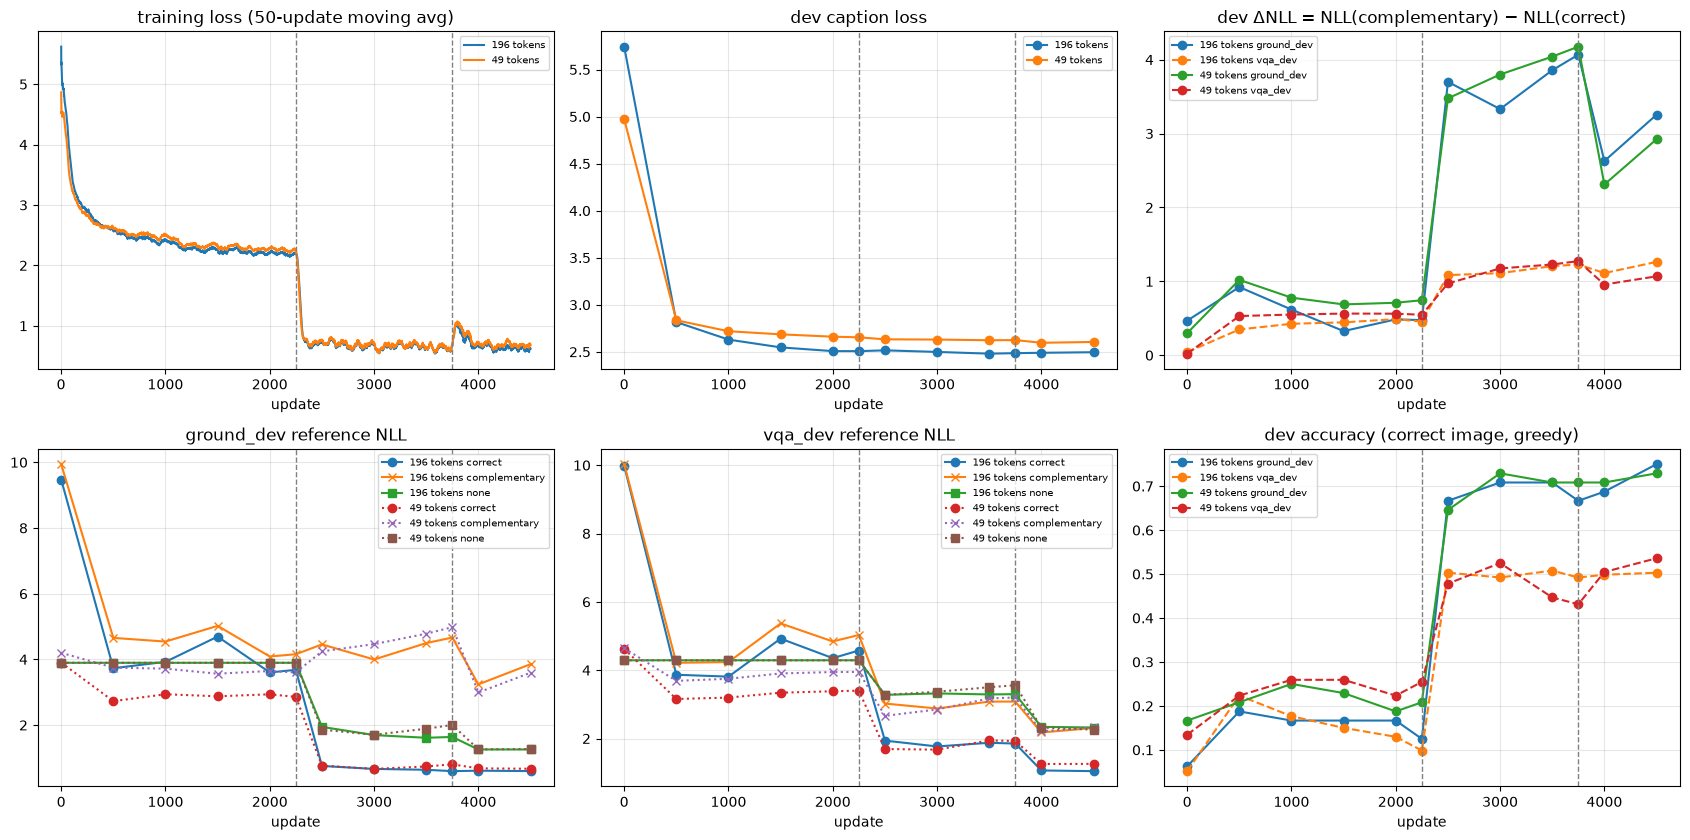

,caption_loss,ground_dev/nll_correct,ground_dev/nll_complementary,ground_dev/nll_none,ground_dev/delta_nll,ground_dev/delta_nll/counting,ground_dev/delta_nll/presence,ground_dev/acc_correct,vqa_dev/nll_correct,vqa_dev/nll_complementary,vqa_dev/nll_none,vqa_dev/delta_nll,vqa_dev/delta_nll/number,vqa_dev/delta_nll/other,vqa_dev/delta_nll/yes/no,vqa_dev/acc_correct,eval_seconds
update,,,,,,,,,,,,,,,,,
0,5.743,9.475,9.942,3.896,0.468,-0.078,1.014,0.062,9.987,10.029,4.290,0.042,-0.187,-0.105,0.342,0.052,19.911
500,2.816,3.732,4.654,3.896,0.922,0.026,1.819,0.188,3.867,4.216,4.290,0.349,0.209,0.769,0.022,0.223,14.379
1000,2.630,3.924,4.543,3.896,0.618,0.058,1.179,0.167,3.812,4.237,4.290,0.426,0.112,0.898,0.163,0.177,14.942
1500,2.548,4.694,5.020,3.896,0.327,0.085,0.569,0.167,4.924,5.369,4.290,0.445,0.152,0.820,0.265,0.150,15.184
2000,2.508,3.602,4.087,3.896,0.485,0.076,0.895,0.167,4.353,4.841,4.290,0.489,0.135,0.996,0.217,0.130,15.376
2250,2.507,3.682,4.157,3.896,0.475,0.091,0.859,0.125,4.576,5.031,4.290,0.455,0.099,0.945,0.202,0.098,15.908
2500,2.516,0.756,4.455,1.945,3.700,1.037,6.362,0.667,1.939,3.024,3.278,1.084,0.879,1.524,0.782,0.503,13.161
3000,2.499,0.666,3.997,1.696,3.331,1.320,5.343,0.708,1.768,2.879,3.320,1.111,0.891,1.682,0.686,0.492,13.112
3500,2.481,0.639,4.496,1.613,3.857,1.952,5.762,0.708,1.876,3.081,3.290,1.205,1.022,1.698,0.835,0.508,13.060


In [12]:
B = [2250, 3750]
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
for k, v in RUNS.items():
    tl = pd.DataFrame(jl(f"{R}/{v}/train_log.jsonl")); dv = pd.DataFrame(jl(f"{R}/{v}/dev_metrics.jsonl")).sort_values("update")
    ax[0, 0].plot(tl["update"], tl.loss.rolling(50, min_periods=1).mean(), label=k)
    ax[0, 1].plot(dv["update"], dv.caption_loss, "o-", label=k)
    for s, ls in [("ground_dev", "-"), ("vqa_dev", "--")]:
        ax[0, 2].plot(dv["update"], dv[f"{s}/delta_nll"], "o" + ls, label=f"{k} {s}")
        ax[1, 2].plot(dv["update"], dv[f"{s}/acc_correct"], "o" + ls, label=f"{k} {s}")
        for c, mk in [("correct", "o"), ("complementary", "x"), ("none", "s")]:
            ax[1, 0 if s == "ground_dev" else 1].plot(dv["update"], dv[f"{s}/nll_{c}"], mk + ("-" if k.startswith("196") else ":"),
                                                     label=f"{k} {c}")
titles = ["training loss (50-update moving avg)", "dev caption loss", "dev ΔNLL = NLL(complementary) − NLL(correct)",
          "ground_dev reference NLL", "vqa_dev reference NLL", "dev accuracy (correct image, greedy)"]
for a, t in zip(ax.flat, titles):
    a.set_title(t); a.set_xlabel("update"); a.legend(fontsize=7); a.grid(alpha=.3)
    for b in B: a.axvline(b, ls="--", c="gray", lw=1)
plt.tight_layout(); plt.show()
dv = {k: pd.DataFrame(jl(f"{R}/{v}/dev_metrics.jsonl")).sort_values("update").set_index("update") for k, v in RUNS.items()}
display(dv["196 tokens"].round(3))

In [13]:
# training loss per component and stage (196 tokens)
tl = pd.DataFrame(jl(f"{R}/run196/train_log.jsonl"))
comp = collections.defaultdict(list)
for _, r in tl.iterrows():
    for c, l in r.comp_loss.items():
        comp[(r.stage, c)].append(l)
display(pd.Series({k: np.mean(v[-100:]) for k, v in comp.items()}, name="mean loss, last 100 updates of stage").unstack().round(3))
print("grad norm (median per stage):", tl.groupby("stage").grad_norm.median().round(2).to_dict(),
      "| skipped updates:", int(tl.skipped.sum()))

,caption,counting,presence,vqa
1,2.186,NaN,NaN,NaN
2,2.010,0.346,0.044,NaN
3,2.081,0.347,0.038,0.487


grad norm (median per stage): {1: 0.75, 2: 3.19, 3: 4.46} | skipped updates: 0


## 5. Final test results (Stage-3 model, greedy decoding, 16 new tokens)

In [14]:
def cond_table(s, suite):
    rows = []
    for c, d in s[suite]["conditions"].items():
        rows.append({"condition": c, "acc": d["acc"], "acc 95% CI": "[%.3f, %.3f]" % tuple(d["acc_ci"]),
                     "pair acc": d["pair_acc"], "pair acc CI": "[%.3f, %.3f]" % tuple(d["pair_acc_ci"]),
                     "identical-answer rate": d["identical_answer_rate"], "empty rate": d["empty_rate"],
                     "ref NLL": d["ref_nll"], "NLL CI": "[%.2f, %.2f]" % tuple(d["ref_nll_ci"]),
                     "gen ms/answer": 1000 * d["gen_seconds_per_answer"]})
    return pd.DataFrame(rows).set_index("condition").round(3)
def type_table(s, suite):
    rows = []
    for c, d in s[suite]["conditions"].items():
        for t, x in d["by_type"].items():
            rows.append(dict(condition=c, type=t, **{k: round(v, 3) for k, v in x.items()}))
    return pd.DataFrame(rows).set_index(["type", "condition"]).sort_index()
def adv_table(s, suite):
    rows = []
    for k, a in s[suite]["advantages"].items():
        for m, x in a.items():
            rows.append(dict(comparison=k, metric=m, mean=round(x["mean"], 3), ci="[%.3f, %.3f]" % tuple(x["ci"])))
    return pd.DataFrame(rows).set_index(["comparison", "metric"])
for run in RUNS:
    for suite in ["ground_test", "vqa_test"]:
        display(Markdown(f"### {run} — `{suite}` ({summ[run][suite]['n_pairs']} pairs)"))
        display(cond_table(summ[run], suite)); display(type_table(summ[run], suite))
        display(Markdown("Advantage of the correct image (positive = correct better; NLL sign flipped), matched pair bootstrap:"))
        display(adv_table(summ[run], suite))

### 196 tokens — `ground_test` (64 pairs)

,acc,acc 95% CI,pair acc,pair acc CI,identical-answer rate,empty rate,ref NLL,NLL CI,gen ms/answer
condition,,,,,,,,,
correct,0.766,"[0.680, 0.844]",0.625,"[0.500, 0.734]",0.156,0.0,0.723,"[0.49, 0.99]",36.086
complementary,0.086,"[0.047, 0.133]",0.000,"[0.000, 0.000]",0.156,0.0,4.301,"[3.81, 4.80]",31.876
mismatched,0.359,"[0.297, 0.414]",0.016,"[0.000, 0.047]",0.734,0.0,2.518,"[2.21, 2.84]",32.884
none,0.359,"[0.305, 0.414]",0.000,"[0.000, 0.000]",1.000,0.0,1.374,"[1.23, 1.53]",17.025


n_pairs    acc  pair_acc  ref_nll  identical_answer_rate  follows_partner_answer  keeps_original_answer
type     condition                                                                                                             
counting complementary       32  0.156     0.000    3.105                  0.281                   0.547                  0.156
         correct             32  0.547     0.281    1.406                  0.281                     NaN                    NaN
         mismatched          32  0.266     0.031    2.566                  0.562                     NaN                    NaN
         none                32  0.219     0.000    1.785                  1.000                     NaN                    NaN
presence complementary       32  0.016     0.000    5.497                  0.031                   0.984                  0.016
         correct             32  0.984     0.969    0.040                  0.031                     NaN                    NaN
         mismatched          32  0.453     0.000    2.471                  0.906                     NaN                    NaN
         none                32  0.500     0.000    0.962                  1.000                     NaN                    NaN

Advantage of the correct image (positive = correct better; NLL sign flipped), matched pair bootstrap:

mean              ci
comparison               metric                         
correct_vs_complementary acc       0.680  [0.562, 0.789]
                         pair_acc  0.625  [0.500, 0.734]
                         nll       3.577  [2.907, 4.252]
correct_vs_mismatched    acc       0.406  [0.320, 0.485]
                         pair_acc  0.609  [0.484, 0.734]
                         nll       1.795  [1.431, 2.164]
correct_vs_none          acc       0.406  [0.328, 0.477]
                         pair_acc  0.625  [0.500, 0.734]
                         nll       0.650  [0.412, 0.881]

### 196 tokens — `vqa_test` (96 pairs)

... (10 outputs left out)

,acc,acc 95% CI,pair acc,pair acc CI,identical-answer rate,empty rate,ref NLL,NLL CI,gen ms/answer
condition,,,,,,,,,
correct,0.616,"[0.550, 0.680]",0.312,"[0.229, 0.406]",0.510,0.0,1.390,"[1.08, 1.76]",22.690
complementary,0.267,"[0.214, 0.318]",0.000,"[0.000, 0.000]",0.510,0.0,3.053,"[2.56, 3.61]",23.117
mismatched,0.328,"[0.269, 0.384]",0.010,"[0.000, 0.031]",0.688,0.0,2.605,"[2.22, 3.05]",22.084
none,0.368,"[0.317, 0.419]",0.000,"[0.000, 0.000]",1.000,0.0,2.271,"[1.89, 2.72]",20.876


n_pairs    acc  pair_acc  ref_nll  identical_answer_rate  follows_partner_answer  keeps_original_answer
type   condition                                                                                                             
number complementary       24  0.144     0.000    4.045                  0.375                   0.604                  0.125
       correct             24  0.629     0.375    1.303                  0.375                     NaN                    NaN
       mismatched          24  0.208     0.000    3.360                  0.750                     NaN                    NaN
       none                24  0.346     0.000    1.977                  1.000                     NaN                    NaN
other  complementary       36  0.186     0.000    4.150                  0.444                   0.472                  0.153
       correct             36  0.501     0.250    2.144                  0.444                     NaN                    NaN
       mismatched          36  0.142     0.000    3.475                  0.361                     NaN                    NaN
       none                36  0.203     0.000    3.583                  1.000                     NaN                    NaN
yes/no complementary       36  0.429     0.000    1.294                  0.667                   0.667                  0.333
       correct             36  0.721     0.333    0.695                  0.667                     NaN                    NaN
       mismatched          36  0.593     0.028    1.232                  0.972                     NaN                    NaN
       none                36  0.549     0.000    1.154                  1.000                     NaN                    NaN

Advantage of the correct image (positive = correct better; NLL sign flipped), matched pair bootstrap:

mean              ci
comparison               metric                         
correct_vs_complementary acc       0.349  [0.264, 0.440]
                         pair_acc  0.312  [0.229, 0.406]
                         nll       1.662  [1.235, 2.131]
correct_vs_mismatched    acc       0.288  [0.216, 0.365]
                         pair_acc  0.302  [0.208, 0.396]
                         nll       1.215  [0.900, 1.562]
correct_vs_none          acc       0.247  [0.179, 0.318]
                         pair_acc  0.312  [0.229, 0.406]
                         nll       0.881  [0.646, 1.141]

*acc* = exact match after VQA normalization for grounding and the local VQA consensus (soft) accuracy for VQAv2;
*pair acc* = both questions of a pair exactly right; *identical-answer rate* = the two questions of a pair received the
same normalized answer; *ref NLL* = teacher-forced token-mean NLL of the original reference answer under that image
condition (termination token excluded).

### Partner-following under the complementary condition

In [15]:
rows = []
for run in RUNS:
    for suite in ["ground_test", "vqa_test"]:
        d = summ[run][suite]["conditions"]["complementary"]
        rows.append(dict(run=run, suite=suite, type="all", follows_partner=d["follows_partner_answer"],
                         keeps_original=d["keeps_original_answer"], other=d["other_answer"], partner_acc=d["partner_acc"]))
        for t, x in d["by_type"].items():
            rows.append(dict(run=run, suite=suite, type=t, follows_partner=x["follows_partner_answer"],
                             keeps_original=x["keeps_original_answer"], other=1 - x["follows_partner_answer"] - x["keeps_original_answer"]))
display(pd.DataFrame(rows).set_index(["run", "suite", "type"]).round(3))

follows_partner  keeps_original  other  partner_acc
run        suite       type                                                         
196 tokens ground_test all                 0.766           0.086  0.148        0.766
                       counting            0.547           0.156  0.297          NaN
                       presence            0.984           0.016  0.000          NaN
           vqa_test    all                 0.615           0.182  0.203        0.647
                       number              0.604           0.167  0.229          NaN
                       other               0.528           0.083  0.389          NaN
                       yes/no              0.708           0.292 -0.000          NaN
49 tokens  ground_test all                 0.711           0.141  0.148        0.711
                       counting            0.453           0.250  0.297          NaN
                       presence            0.969           0.031  0.000          NaN
           vqa_test    all                 0.578           0.214  0.208        0.616
                       number              0.604           0.125  0.271          NaN
                       other               0.472           0.153  0.375          NaN
                       yes/no              0.667           0.333  0.000          NaN

When the partner image is shown, a grounded model should *change* its answer to the partner's answer
("follows partner"); keeping the original answer means the question/prior, not the image, decided it.

## 6. Qualitative complementary examples

Selection rule (fixed before looking at outputs): for each suite and question type, the first two pairs in sorted
`pair_id` order. Each row shows the 196-token model's answers to the same question on image A and image B (correct
condition) and with the images swapped (complementary). Images are loaded from `images.cocodataset.org`.

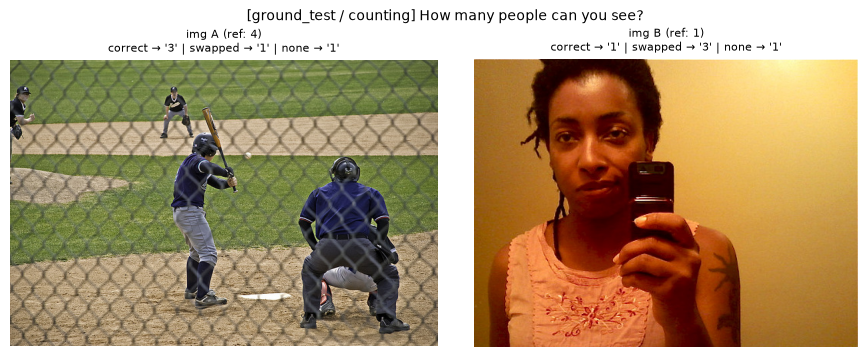

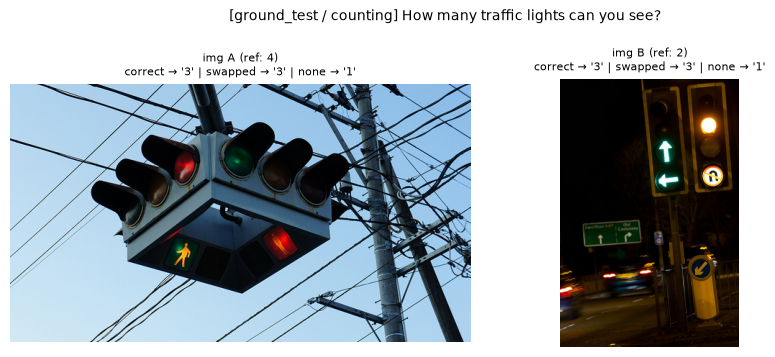

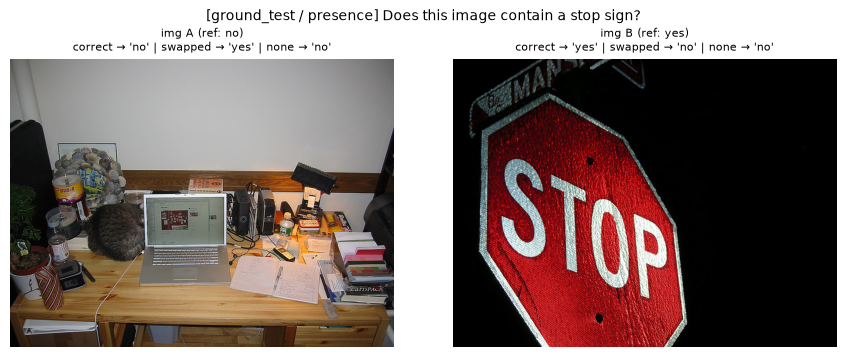

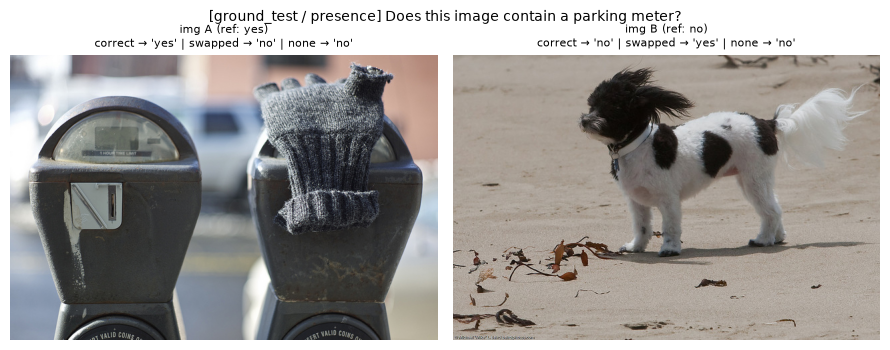

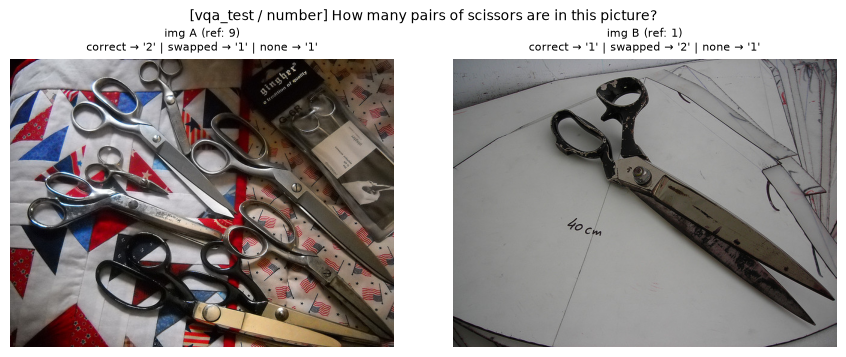

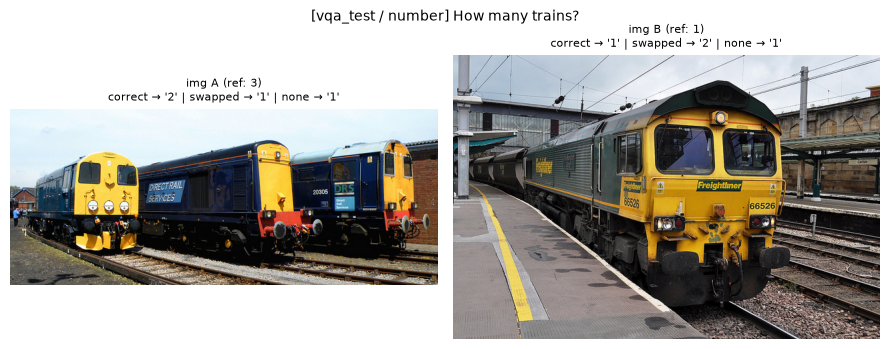

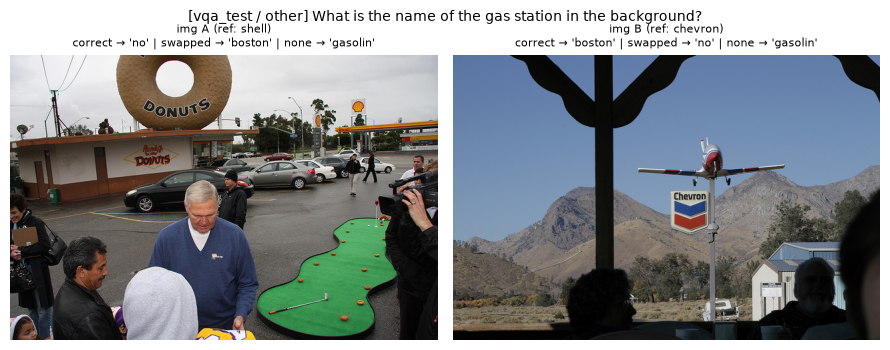

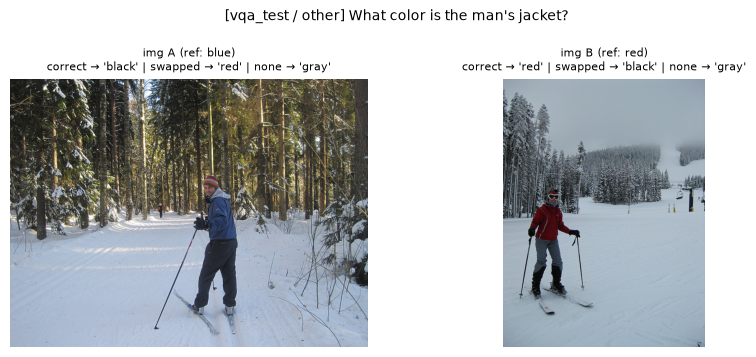

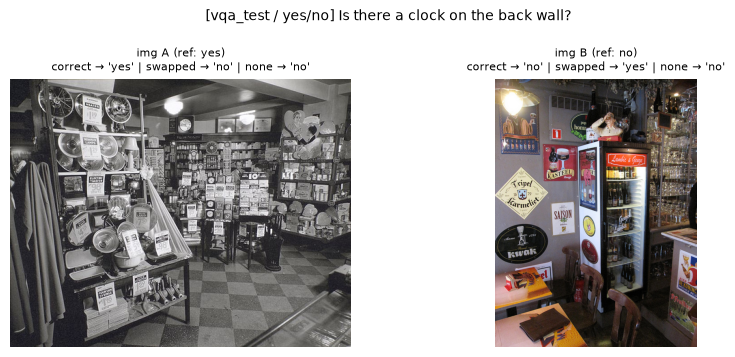

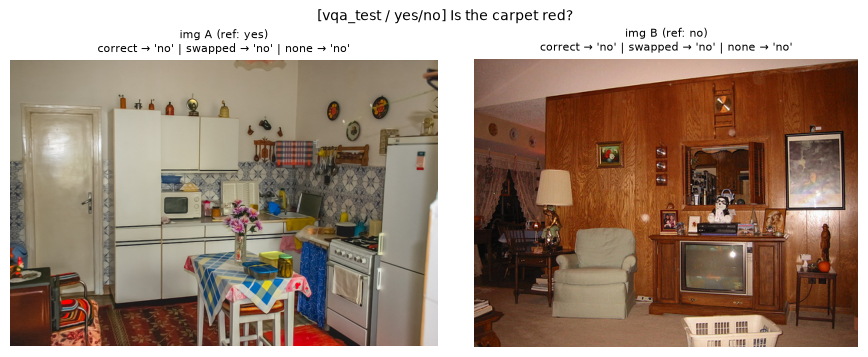

In [16]:
from PIL import Image
def recs(run, suite, cond):
    return {r["qid"]: r for r in jl(f"{R}/{RUNS[run]}/final/{suite}_{cond}.jsonl")}
def load_img(e):
    fn = sel["image_files"][f"{e['split']}/{e['image_id']}"]
    try:
        return Image.open(io.BytesIO(urllib.request.urlopen(f"http://images.cocodataset.org/val2014/{fn}", timeout=20).read()))
    except Exception as ex:
        return None
for suite in ["ground_test", "vqa_test"]:
    cor, com, non = recs("196 tokens", suite, "correct"), recs("196 tokens", suite, "complementary"), recs("196 tokens", suite, "none")
    byt = collections.defaultdict(list)
    for p in sorted(sel[suite], key=lambda p: p[0]["pair_id"]):
        byt[p[0]["type"]].append(p)
    for t, ps in sorted(byt.items()):
        for p in ps[:2]:
            fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
            for j in range(2):
                e = p[j]; im = load_img(e); a = ax[j]
                if im is not None: a.imshow(im)
                a.axis("off")
                a.set_title(f"img {'AB'[j]} (ref: {e['target']})\ncorrect → {cor[e['qid']]['prediction']!r}"
                            f" | swapped → {com[e['qid']]['prediction']!r} | none → {non[e['qid']]['prediction']!r}", fontsize=8)
            fig.suptitle(f"[{suite} / {t}] {p[0]['question']}", fontsize=10); plt.tight_layout(); plt.show()

## 7. Resources

In [17]:
rows = []
for run, v in RUNS.items():
    d = json.load(open(f"{R}/{v}/DONE.json"))
    for st, x in d["stages"].items():
        rows.append(dict(run=run, stage=st, trainable_params=x["trainable_params"], train_minutes=x["train_seconds"] / 60,
                         sec_per_update=x["train_seconds"] / {"caption_alignment": 2250, "visual_instruction": 1500, "natural_vqa": 750}[st],
                         peak_gpu_mem_gb=x["peak_gpu_mem_gb"], skipped_updates=len(x["skipped_updates"])))
display(pd.DataFrame(rows).set_index(["run", "stage"]).round(3))
c = json.load(open(f"{R}/data/cache_stats.json")); f = json.load(open(f"{R}/data/fetch_stats.json"))
print(f"SigLIP cache: {c['images']} images in {c['seconds']:.0f}s ({c['images']/c['seconds']:.0f} img/s), "
      f"{c['bytes']/2**30:.2f} GiB fp16, peak {c['peak_gpu_mem_gb']:.2f} GB, vision params {c['vision_params']:,} (frozen, run once);"
      f" image download {f['bytes']/2**30:.2f} GiB in {f['seconds']:.0f}s")
g = pd.DataFrame({run: {f"{s}/{cnd}": 1000 * summ[run][s]["conditions"][cnd]["gen_seconds_per_answer"]
                        for s in ["ground_test", "vqa_test"] for cnd in summ[run][s]["conditions"]} for run in RUNS})
display(g.round(1).rename_axis("generation ms / answer (batch 8, T4)"))
print("final-eval peak GPU memory (GB):", {r: round(summ[r]["peak_gpu_mem_gb"], 2) for r in RUNS})

trainable_params  train_minutes  sec_per_update  peak_gpu_mem_gb  skipped_updates
run        stage                                                                                                
196 tokens caption_alignment            1837056         46.255           1.233            1.704                0
           visual_instruction           6424576         34.828           1.393            1.757                0
           natural_vqa                  6424576         17.133           1.371            1.757                0
49 tokens  caption_alignment            1837056         19.089           0.509            1.471                0
           visual_instruction           6424576         18.485           0.739            1.471                0
           natural_vqa                  6424576          9.209           0.737            1.422                0

SigLIP cache: 17961 images in 156s (115 img/s), 5.04 GiB fp16, peak 1.20 GB, vision params 92,884,224 (frozen, run once); image download 2.70 GiB in 50s


,196 tokens,49 tokens
"generation ms / answer (batch 8, T4)",,
ground_test/correct,36.1,22.2
ground_test/complementary,31.9,17.7
ground_test/mismatched,32.9,18.3
ground_test/none,17.0,18.1
vqa_test/correct,38.6,22.7
vqa_test/complementary,38.6,23.1
vqa_test/mismatched,38.0,22.1
vqa_test/none,19.8,20.9


final-eval peak GPU memory (GB): {'196 tokens': 1.6, '49 tokens': 1.32}


## 8. 196 vs 49 visual tokens

In [18]:
rows = []
for run in RUNS:
    for suite in ["ground_test", "vqa_test"]:
        cs, ad = summ[run][suite]["conditions"], summ[run][suite]["advantages"]
        rows.append(dict(run=run, suite=suite, acc_correct=cs["correct"]["acc"], pair_acc_correct=cs["correct"]["pair_acc"],
                         nll_correct=cs["correct"]["ref_nll"],
                         adv_vs_complementary=ad["correct_vs_complementary"]["acc"]["mean"],
                         adv_vs_none=ad["correct_vs_none"]["acc"]["mean"],
                         follows_partner=cs["complementary"]["follows_partner_answer"],
                         gen_ms=1000 * cs["correct"]["gen_seconds_per_answer"]))
display(pd.DataFrame(rows).set_index(["suite", "run"]).sort_index().round(3))
# paired difference 196 - 49 on the same test pairs (bootstrap over pairs)
for suite in ["ground_test", "vqa_test"]:
    a = {run: np.array([r["acc"] for r in jl(f"{R}/{RUNS[run]}/final/{suite}_correct.jsonl")]).reshape(-1, 2).mean(1) for run in RUNS}
    d = a["196 tokens"] - a["49 tokens"]
    idx = np.random.default_rng(6304).integers(0, len(d), size=(4000, len(d)))
    bs = d[idx].mean(1)
    print(f"{suite}: acc(196) - acc(49) = {d.mean():+.3f}, 95% CI [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]")

acc_correct  pair_acc_correct  nll_correct  adv_vs_complementary  adv_vs_none  follows_partner  gen_ms
suite       run                                                                                                               
ground_test 196 tokens        0.766             0.625        0.723                 0.680        0.406            0.766  36.086
            49 tokens         0.711             0.562        0.749                 0.570        0.367            0.711  22.244
vqa_test    196 tokens        0.647             0.385        1.362                 0.403        0.288            0.615  38.644
            49 tokens         0.616             0.312        1.390                 0.349        0.247            0.578  22.690

ground_test: acc(196) - acc(49) = +0.055, 95% CI [+0.008, +0.109]
vqa_test: acc(196) - acc(49) = +0.032, 95% CI [-0.019, +0.084]


## 9. Discussion

**Does the model use the image?** Yes, clearly and on both suites. On the grounding test the correct image gives
accuracy 0.766 [0.680, 0.844] versus 0.359 with no image and
0.359 with a mismatched image; the correct-vs-complementary advantage is
0.680 [0.562, 0.789] in accuracy and
3.577 nats in reference NLL. On VQAv2 the correct image reaches
0.647 [0.581, 0.715] against 0.360 without an image, and the
advantage over the complementary image is 0.403
[0.309, 0.496]. All advantage CIs exclude zero.

**Accuracy alone overstates grounding; pair metrics expose it.** With no image the model answers both questions of a
pair identically (identical-answer rate 1.0 by construction), so its pair accuracy is 0 even though single-question
accuracy is ≈ 0.359/0.360 (answer-prior guessing, e.g. always "yes" gets half the
presence questions). With the correct image the identical-answer rate drops to 0.156
(grounding) and 0.375 (VQA), and pair accuracy rises to
0.625 and 0.385.

**Complementary images.** When the partner image is shown, the answer follows the partner's answer
0.766 (grounding) / 0.615 (VQA)
of the time and keeps the original only 0.086 /
0.182: answers are mostly driven by the image. Presence is almost perfectly
grounded (correct 0.984, follows partner
0.984); counting is the weak spot (correct
0.547, pair acc 0.281):
the connector conveys *what* is in the image far better than *how many*. For VQA, "other" questions benefit most
from the image relative to the no-image prior, yes/no questions least (their prior is already ≈ 0.5).

**What each stage contributes (dev curves).** Stage 1 lowers dev caption loss from ≈ 5.7 to ≈ 2.5, but the
grounding/VQA ΔNLL stays small (< 1 nat) and dev accuracy stays near chance: caption alignment alone teaches the LM to
*describe* images, not to answer short questions about them. The jump happens at the start of Stage 2 (LoRA +
presence/counting data): ground_dev ΔNLL rises to ≈ 3.5–4 nats and accuracy to ≈ 0.7 within 250 updates, and VQA dev
accuracy also jumps to ≈ 0.5 although no VQA data has been seen yet. Stage 3 (natural VQA) keeps VQA ΔNLL around
1.1–1.3 and slightly lowers the grounding ΔNLL (the presence/counting share drops from 75 % to 20 %), with caption loss
essentially unchanged — no forgetting of the caption ability.

**196 vs 49 tokens.** Average-pooling to 49 tokens costs a little everywhere (correct-image accuracy
0.766 → 0.711
on grounding, 0.647 → 0.616
on VQA), mostly on counting, while cutting training time per update by more than half and generation time by roughly 40 %. On the same test pairs
the paired difference (section 8) is +0.055 [+0.008, +0.109] on grounding (CI excludes zero, driven by counting) but
+0.032 [−0.019, +0.084] on VQA (CI includes zero): spatial resolution matters for counting, much less for VQAv2.

**Limitations.** Test sets are small (64 and 96 pairs), so CIs are ±5–10 points; one seed per recipe; the
synthetic grounding labels inherit COCO annotation errors (missed instances inflate counting errors); greedy decoding
with a 16-token budget; the no-image condition removes visual tokens entirely, so it also shortens the prompt.